# BRFSS 2021 GENHLTH — Personal Learning Walkthrough

> ## ⚠️ PERSONAL LEARNING ARTIFACT — NOT A COURSE DELIVERABLE
> The **evaluated deliverable is `deliverables/code.py`** (self-contained, runs end-to-end) together with
> `deliverables/report/report.pdf`. This notebook is my own step-by-step **replay** of the project so I can
> learn, verify and internalize every moving part. It is header-marked as a personal artifact and should never
> be confused with the submission.

**What this notebook is.** A faithful **full-data replay** of the entire project pipeline:

- the **canonical folds** come from `src/config.py:make_folds()` — `StratifiedKFold(10, shuffle=True, random_state=42)` — the one and only splitter used anywhere in the project;
- tuned hyperparameters come verbatim from `results/p6/best_params.json`;
- every model pipeline is **reused from `src/`** (never re-implemented), so the fold scores below must match `results/experiments_log.csv` to the log's 6-decimal rounding — that is the notebook's whole point. A final self-check cell (section 14) verifies this programmatically, row by row.

**How to run.** From the repo root:

```
python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 notebooks/BRFSS_walkthrough.ipynb
```

Requires `data/raw/LLCP2021.csv` (immutable raw data, gitignored) and the `data/interim/` checkpoints. The notebook itself **writes nothing** — `src/`, `results/`, `vault/`, `deliverables/` are read-only here.

### Runtime map (measured on the project machine: 12 logical cores)

| # | section | expected wall time |
|---|---|---|
| 1 | setup + canonical fold hash | ~15 s |
| 2 | raw CSV load + first look (262 MiB) | 10–60 s |
| 3 | target framing (ADR-001) | ~3 s |
| 4 | leakage probe (`_RFHLTH`) | ~5 s |
| 5 | triage demos + the ρ flip | ~15 s |
| 6 | rebuild matrix, verify cache, `load_xy` | 1–2 min |
| 7 | EDA (imbalance, association, correlation, key features) | 2–3 min |
| 8 | baselines: Dummy, 2× LogReg, 2× DecisionTree | 3–5 min |
| 9 | model zoo: RF + HistGB + LGBM + XGB | **12–25 min** |
| 9b | GPU explainer + Colab companion cell | ~0 s (skipped locally) |
| 10 | imbalance: XGB spw / SMOTE / RUS + LogReg balanced | **10–15 min** |
| 11 | selection: kbest-200 + importances + H1/complement + PCA-100 | **15–25 min** |
| 12 | tuning replay (~70 s) + Wilcoxon + nested-CV read-back | 2–3 min |
| 13 | error taxonomy + selected cases + stored SHAP | 1–2 min |
| 14 | conclusions + programmatic self-check | ~5 s |
| | **total** | **~40–80 min** (measured ~42 min on an idle 12-core machine) |

The original experiments' logged CV walls sum to ≈ 2.5 h of compute (see the `runtime_s=` fields in the log); this replay skips only the full RandomizedSearch (~22 min) and full nested CV (~26 min), whose results are loaded from committed artifacts instead.

### Project map — where the real things live

| artifact | what it is |
|---|---|
| `deliverables/code.py` | **the graded deliverable** — self-contained pipeline, reproduces EXP-014a via `--full` |
| `deliverables/report/report.pdf` | the graded report (every number cites an EXP id) |
| `results/experiments_log.csv` | append-only log, 42 rows — the single source of truth for every score |
| `src/config.py`, `src/preprocessing.py`, `src/experiments.py` | constants/target, cleaning/whitelist, CV harness |
| `src/p4_models.py` … `src/p7_error_xai.py` | model zoo, selection/tuning, error analysis + SHAP |
| `vault/30 Decisions/ADR-001…006` | architecture decision records (referenced throughout) |
| `vault/40 Data Notes/Leakage watchlist.md` | the leakage blacklist + tier model |
| `figures/` | all committed figures (PNG, dpi ≥ 150) |

## 1 — Setup: one splitter to rule them all

**WHAT.** Import the project's own modules (`src/…`), print the fixed constants, materialize the canonical folds and hash them.

**WHY one fixed splitter?** Every model in this project — baselines, zoo, imbalance variants, selection runs, tuned finals — is scored by the same `StratifiedKFold(n_splits=10, shuffle=True, random_state=42)` from `src/config.py:make_folds()`. Because every AUC in the log is computed on the *same* 10 test partitions, all comparisons are **paired**, which is precisely what licenses the Wilcoxon signed-rank tests in section 12 (10 paired fold AUCs per model). The fold assignment is hashed (sha256 over the fold index arrays); the hash prefix `3b3a17457039` is recorded in the `notes` field of every scored row of `results/experiments_log.csv`, so fold identity is auditable across sessions — and this notebook asserts it too.

Only `random_state=42` is ever used (AGENTS.md rule: no other seed may exist in committed code).

In [1]:
%matplotlib inline
import sys, time, json, hashlib, warnings, contextlib, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

# put the repo root on sys.path so `import src...` works no matter where the kernel starts
ROOT = Path.cwd()
for _cand in [ROOT, *ROOT.parents]:
    if (_cand / "src" / "config.py").exists():
        ROOT = _cand
        break
else:
    raise RuntimeError("cannot locate the repo root (src/config.py) - run this notebook from the repo or notebooks/ dir")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)

from src.config import (RANDOM_STATE, N_SPLITS, POSITIVE_CLASSES, NEGATIVE_CLASSES, TARGET_COL,
                        DATA_RAW, DATA_INTERIM, RESULTS, EXPERIMENTS_LOG, make_folds)
from src.experiments import make_fold_list, fold_list_hash, load_xy, build_preprocessor

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print(f"RANDOM_STATE={RANDOM_STATE} | N_SPLITS={N_SPLITS} | y=1 iff GENHLTH in {POSITIVE_CLASSES}, y=0 iff in {NEGATIVE_CLASSES}")
print("the one and only splitter:", make_folds())

# per-section wall-clock bookkeeping (printed again in the section-14 self-check)
SECTION_TIMES = {}
@contextlib.contextmanager
def timed(name):
    t0 = time.perf_counter()
    yield
    dt = time.perf_counter() - t0
    SECTION_TIMES[name] = SECTION_TIMES.get(name, 0.0) + dt
    print(f"[section time] {name}: {dt:.1f}s")

# materialize the canonical folds NOW using only y (StratifiedKFold's split depends on n and y),
# then hash them exactly like the harness does (sha256 over the fold index arrays)
with timed("S1 setup + fold hash"):
    _tgt = pd.read_parquet(DATA_INTERIM / "target_v1.parquet")
    _y = _tgt.loc[_tgt["valid"].to_numpy(bool), "y"].to_numpy()
    folds, FOLD_HASH = make_fold_list(np.zeros((len(_y), 1)), _y)
    print("folds_sha256 =", FOLD_HASH)
    assert FOLD_HASH.startswith("3b3a17457039"), "canonical fold hash drifted vs the log prefix!"
    sizes = [len(te) for _, te in folds]
    print(f"10 test folds, sizes {min(sizes):,}..{max(sizes):,} (sum {sum(sizes):,}); "
          f"positive rate per fold: {np.round([_y[te].mean() for _, te in folds], 5)}")

repo root: C:\Users\Hassene\Documents\Machine learning final project


RANDOM_STATE=42 | N_SPLITS=10 | y=1 iff GENHLTH in (4, 5), y=0 iff in (1, 2, 3)
the one and only splitter: StratifiedKFold(n_splits=10, random_state=42, shuffle=True)
folds_sha256 = 3b3a17457039b2589ce4f26a51d90bbd116573f0d692889d0bd24259075f78b7
10 test folds, sizes 43,753..43,754 (sum 437,532); positive rate per fold: [0.16627 0.16625 0.16625 0.16625 0.16625 0.16625 0.16625 0.16625 0.16625
 0.16625]
[section time] S1 setup + fold hash: 0.2s


**Interpretation.** The fold hash matches the `folds_sha256=3b3a17457039` prefix recorded in all 41 scored rows of the log — this notebook is literally scoring on the same row partitions as every logged experiment. `make_fold_list` also internally asserts the 10 test folds partition the 437,532 valid rows exactly once with no train/test overlap, and each fold keeps the 16.6% positive rate (stratification working as intended). Rebuilding the splitter from scratch is bit-identical (the harness asserts this on every run; we re-verify in section 6 on the real matrix).

## 2 — Load the raw data & first look

**WHAT.** Read `data/raw/LLCP2021.csv` (immutable, gitignored; 274,338,975 bytes ≈ 262 MiB; ~10–30 s), census the dtypes, and look at the interview-mode columns.

**WHY.** BRFSS 2021 is a **dual-frame telephone survey** (landline + cell phone). Respondents are sampled through two frames, and the first block of questionnaire columns is *interview logistics* that differs by mode (which adult was selected, how many adults/children in the household, cell-vs-landline state codes…). That structure matters later: ADR-005 rule 2 drops this whole flow block because it is admin, not respondent health content. All 303 columns are read here once; sections 3–5 probe them; section 6 reduces them to the 76-column whitelist.

In [2]:
from src.preprocessing import load_raw

with timed("S2 raw load + first look"):
    df = load_raw()                      # pd.read_csv(..., low_memory=False) - one pass, ~262 MiB
    print("\ndtype census:")
    print(df.dtypes.astype(str).value_counts().to_string())
    print(f"\ncensus-constant columns (<=1 distinct value): {int((df.nunique(dropna=True) <= 1).sum())}")
    mode_cols = ["CTELENM1", "PVTRESD1", "LADULT1", "NUMADULT", "CELLSEX", "CSTATE1",
                 "LANDLINE", "HHADULT", "NUMHHOL3", "CPDEMO1B"]
    share = df[mode_cols].notna().mean().round(3).sort_values()
    print("\ninterview-mode flow columns - share of rows with a value (blank = not asked in that frame):")
    print(share.to_string())

[p2] reading C:\Users\Hassene\Documents\Machine learning final project\data\raw\LLCP2021.csv ...


[p2] raw shape = 438,693 rows x 303 cols

dtype census:
float64    245
int64       58



census-constant columns (<=1 distinct value): 11

interview-mode flow columns - share of rows with a value (blank = not asked in that frame):
CTELENM1    0.268
PVTRESD1    0.268
LADULT1     0.268
NUMADULT    0.268
NUMHHOL3    0.268
CELLSEX     0.732
CSTATE1     0.732
LANDLINE    0.732
HHADULT     0.732
CPDEMO1B    0.999
[section time] S2 raw load + first look: 6.8s


**Interpretation — what the log/profiling recorded and this cell reproduces.** Shape is exactly **438,693 × 303**. Almost everything is numeric dtype only because blanks force float columns — the data is really a mix of small category codes and a handful of day/count variables. 11 columns are census-constant (e.g. `CELPHON1`, `SAFETIME`, `CTELNUM1` — 2021 cell-frame constants) plus `IYEAR` with 2 values; these die under ADR-005 rule 3. The mode-flow columns show the two-frame structure directly: several (`CTELENM1`, `LANDLINE`, `NUMHHOL3`, `CPDEMO1B`…) are blank for large shares of rows because they are only asked in one frame — that is questionnaire logistics, not missing health information, and exactly why they are dropped rather than imputed.

## 3 — Target & problem framing (ADR-001)

**WHAT.** `GENHLTH` is natively 5-class (1 Excellent … 5 Poor) plus sentinels 7 = Don't know, 9 = Refused, and blanks. **ADR-001** frames the task as binary: **y = 1 iff GENHLTH ∈ {4,5} (Fair/Poor), y = 0 iff GENHLTH ∈ {1,2,3}**; rows with GENHLTH ∈ {7, 9, blank} are **dropped, not imputed** (~1,161 rows). The recode lives in `src/config.py:make_target()`.

**WHY this framing.** (1) It matches the CDC's own calculated variable `_RFHLTH` (adults with fair/poor health) — a citable external definition; (2) it leaves a workable 16.6% positive rate — realistic imbalance that still gives stable 10-fold scores and a rich error-analysis pool. **Alternatives ADR-001 rejected:** *Poor-only vs rest* (4.1% positives — thin folds, noisy scores); *keep 5-class as the main task* (contradicts the binary objective; multiclass explicitly declined in ADR-002); *Good-or-better vs rest* (identical split with flipped labels — not a distinct experiment).

In [3]:
from src.config import make_target

labels = {1.0: "1 Excellent", 2.0: "2 Very good", 3.0: "3 Good", 4.0: "4 Fair", 5.0: "5 Poor",
          7.0: "7 Don't know", 9.0: "9 Refused", np.nan: "blank"}

with timed("S3 target framing"):
    dist = df[TARGET_COL].value_counts(dropna=False).sort_index()
    tab = pd.DataFrame({"code": [labels.get(c, c) for c in dist.index],
                        "n": dist.values,
                        "pct": (100 * dist.values / dist.sum()).round(2)})
    print(tab.to_string(index=False))
    y_all, valid = make_target(df[TARGET_COL])          # the ADR-001 recode, verbatim from src
    n_valid, n_pos = int(valid.sum()), int(y_all[valid].sum())
    rate = 100.0 * n_pos / n_valid
    print(f"\nvalid rows: {n_valid:,} | dropped (7/9/blank): {len(df) - n_valid:,} | "
          f"positives: {n_pos:,} | positive rate: {rate:.2f}%")
    assert (n_valid, n_pos) == (437_532, 72_741) and abs(rate - 16.63) < 0.01

        code      n   pct
 1 Excellent  77741 17.72
 2 Very good 149112 33.99
      3 Good 137938 31.44
      4 Fair  54736 12.48
      5 Poor  18005  4.10
7 Don't know    788  0.18
   9 Refused    369  0.08
         NaN      4  0.00

valid rows: 437,532 | dropped (7/9/blank): 1,161 | positives: 72,741 | positive rate: 16.63%
[section time] S3 target framing: 0.0s


**Interpretation.** 438,693 − 437,532 = **1,161 dropped rows**; **72,741 positives = 16.63%** — exactly the numbers asserted by the cleaning sanity gates and quoted in every summary. Class counts: Excellent 77,741 / Very good 149,112 / Good 137,938 / Fair 54,736 / Poor 18,005 (17.7% / 34.0% / 31.4% / 12.5% / 4.1%, matching ADR-001). The 16.6% imbalance is the reason section 10 exists (SMOTE / class weights / undersampling) and the reason the final model's default threshold produces a 46% false-negative rate (section 13) — the framing decision echoes all the way through the project.

## 4 — The leakage story (live probe)

**WHAT.** `_RFHLTH` is the CDC's own calculated fair/poor flag, computed *from GENHLTH*. We cross-tabulate it against the raw target and measure agreement with our binary y.

**WHY this matters more than any model choice.** A single leaked column of this kind yields ≈ 1.00 AUC and renders the whole project meaningless. The project's defense has two layers (see `vault/40 Data Notes/Leakage watchlist.md`):

- **Tier 1 — direct target derivation (absolute blacklist):** `GENHLTH` itself, `_RFHLTH`, `_PHYS14D`, `_MENT14D`. Hard-asserted absent from the matrix in `src/preprocessing.py` — `build_clean` *raises* if any of them is present.
- **Tier 2 — duplicates of kept features** (e.g. `_BMI5CAT` vs `_BMI5`, `_SMOKER3` vs `SMOKE100`…): resolved by ADR-005 rule 6, keep ONE representation per pair.
- **Tier 3 — construct suspicion** (measures something *near* the target, e.g. `PHYSHLTH`/`POORHLTH` health-days items): resolved with data evidence in ADR-004 — strong association (ρ ≈ −0.29) is fine; being *derived* (100% agreement) is not.

And the structural principle: the matrix is built **by whitelist (build-by-inclusion)** — 76 named columns — so a typo in a drop-list *cannot* leak the target. A blacklist alone would be fragile (forget one name and you leak); the blacklist survives as a second, hard assertion.

In [4]:
from src.preprocessing import BLACKLIST

with timed("S4 leakage probe"):
    gh_valid = df.loc[valid, TARGET_COL]
    rf_valid = df.loc[valid, "_RFHLTH"]
    ct = pd.crosstab(gh_valid, rf_valid, margins=True)
    print("crosstab GENHLTH (rows) x _RFHLTH (columns), valid rows only:")
    print(ct.to_string())
    yb = y_all[valid].to_numpy()
    agree = (gh_valid.isin([4, 5]).to_numpy() == (rf_valid.to_numpy() == 2)).mean()
    print(f"\nagreement of (_RFHLTH == 2) with y on valid rows: {agree:.4%}")
    print("_RFHLTH coding: 1 = Good or better, 2 = Fair/Poor (2 IS y=1), 9 = refused")
    print("\nhard blacklist (never in the matrix; build_clean raises if present):", BLACKLIST)

crosstab GENHLTH (rows) x _RFHLTH (columns), valid rows only:
_RFHLTH       1      2     All
GENHLTH                       
1.0       77741      0   77741
2.0      149112      0  149112
3.0      137938      0  137938
4.0           0  54736   54736
5.0           0  18005   18005
All      364791  72741  437532

agreement of (_RFHLTH == 2) with y on valid rows: 100.0000%
_RFHLTH coding: 1 = Good or better, 2 = Fair/Poor (2 IS y=1), 9 = refused

hard blacklist (never in the matrix; build_clean raises if present): ('GENHLTH', '_RFHLTH', '_PHYS14D', '_MENT14D')
[section time] S4 leakage probe: 0.1s


**Interpretation.** The crosstab is **perfectly diagonal**: every GENHLTH ∈ {1,2,3} row has `_RFHLTH = 1`, every {4,5} row has `_RFHLTH = 2` — agreement **100.0%** (the EXP-000 finding that sealed the Tier-1 blacklist). This is what *derivation* looks like, as opposed to *association*: `PHYSHLTH` correlates with the target at only ρ = −0.29 and measures a genuinely different construct (days of poor physical health), which is why ADR-004 kept it — and why it later turns out to be the single most important feature (sections 11/13). The empirical discriminator between "leakage" and "strong predictor" is not the size of the association but its *mechanism*.

## 5 — Column triage: 303 → 76 (ADR-005)

**WHAT.** ADR-005 reduces the 303 raw columns to a frozen 76-column whitelist with **seven rules**, precedence **R1 > R3 > R2 > R6 > R4 > R5 > keep** (first matching verdict wins; every one of the 303 columns gets an explicit verdict + reason in `results/profiling/triage_decisions.csv` — no silent drops):

| rule | verdict | catches | n |
|---|---|---|---|
| R1 | DROP-LEAK | target source & its calculated derivatives (`GENHLTH`, `_RFHLTH`, `_PHYS14D`, `_MENT14D`) | 4 |
| R2 | DROP-ID / DROP-MODE | identifiers, dates, dispatch, weights/strata, instrument admin, landline/cell flow block | 18 + 16 |
| R3 | DROP-CONSTANT | census-constant columns (≤1 distinct value) + `IYEAR` | 12 |
| R4 | DROP-SPARSE | >90% blank + sentinel (micro-coverage modules) | 86 |
| R5 | DROP-MODULE | 10–25% *effective* coverage after sentinel recode (optional modules) | 26 |
| R6 | DROP-DUP | one representation per duplicate pair / computed family — **keep the raw/simplest** (`_BMI5` over height+weight+bins, `EDUCA` over `_EDUCAG`, `EXERANY2` ≡ `_TOTINDA` proven identical…) | 65 |
| R7 | judgment protocol | ambiguous columns get a *recorded* call (QSTLANG kept / QSTVER dropped, `_URBSTAT` kept / `_METSTAT` dropped, `_STATE` kept, `CHOLCHK3` kept as NOMINAL because its code order is non-monotone, …) | — |

**The sentinel trap (why "7/9 = missing" pattern-matching is wrong).** BRFSS uses 7/77/777 = Don't know and 9/99/999 = Refused *in many columns — but not all*: `EMPLOY1` code 7 = **Retired** (131,546 rows!), `INCOME3`/`PRIMINSR` codes 7/9 are valid brackets/plans, `_RACE` 7 = Multiracial, `_STATE` 9 = **Connecticut** (FIPS), `_AGE80` 77 = age 77, and 6-digit sentinels 777777/999999 exist too. A generic scan overcounts sentinels for those columns; the cleaning therefore uses **per-column value contracts** (codebook-exact sets, asserted after recode). Three live demos below — including the most dramatic consequence: the **ρ flip** on `PHYSHLTH`, where `88` means *"zero days"* (not missing!) and, if left as the number 88, *inverts* the feature's correlation with the target.

In [5]:
from scipy import stats

with timed("S5 sentinel traps + rho flip"):
    emp = df["EMPLOY1"].value_counts(dropna=False).sort_index()
    print("EMPLOY1 counts (code: n):", {int(k) if pd.notna(k) else "NaN": int(v) for k, v in emp.items()})
    print(f"  -> code 7 = 'Retired' is VALID: {int(emp.get(7.0, 0)):,} rows; only code 9 (Refused) is a sentinel here\n")
    print(f"_STATE == 9 (Connecticut, valid FIPS): {int((df['_STATE'] == 9).sum()):,} rows")
    print(f"PHYSHLTH == 88 ('none' = ZERO days, not missing): {int((df['PHYSHLTH'] == 88).sum()):,} rows\n")

    # the rho flip: raw code 88 ranks ABOVE 30 while meaning ZERO
    yv = y_all[valid].astype(float).to_numpy()
    raw_p = df.loc[valid, "PHYSHLTH"].astype(float).to_numpy()
    rec_p = pd.Series(raw_p).where(~pd.Series(raw_p).isin([77, 99])).replace({88: 0.0}).to_numpy()
    m_raw, m_rec = ~np.isnan(raw_p), ~np.isnan(rec_p)   # scipy.spearmanr is not NaN-aware
    rho_raw = stats.spearmanr(raw_p[m_raw], yv[m_raw]).statistic
    rho_rec = stats.spearmanr(rec_p[m_rec], yv[m_rec]).statistic
    print(f"Spearman rho(PHYSHLTH, y):  raw (88 kept as 88) = {rho_raw:+.3f}   ->   recoded (88->0, 77/99->NaN) = {rho_rec:+.3f}")
    print("  the feature's direction FLIPS with one recode: 287,796 'zero days' rows were ranked as the UNHEALTHIEST")

EMPLOY1 counts (code: n): {1: 186076, 2: 37759, 3: 11406, 4: 9713, 5: 17579, 6: 10661, 7: 131546, 8: 25702, 9: 4663, 'NaN': 3588}
  -> code 7 = 'Retired' is VALID: 131,546 rows; only code 9 (Refused) is a sentinel here

_STATE == 9 (Connecticut, valid FIPS): 8,341 rows
PHYSHLTH == 88 ('none' = ZERO days, not missing): 287,796 rows



Spearman rho(PHYSHLTH, y):  raw (88 kept as 88) = -0.284   ->   recoded (88->0, 77/99->NaN) = +0.450
  the feature's direction FLIPS with one recode: 287,796 'zero days' rows were ranked as the UNHEALTHIEST
[section time] S5 sentinel traps + rho flip: 0.1s


**Interpretation.** Three codebook traps, live: `EMPLOY1` 7 = **131,546 retired respondents** (a generic 7/9 scan would have NaN'd a quarter of the workforce variable); `_STATE` 9 = **8,341 Connecticut rows** (dropping "sentinel 9" would have deleted a state); `PHYSHLTH` 88 = **287,796 zero-day rows** — and the ρ flip **≈ −0.28 → +0.45 on valid rows** (EXP-000's census-wide scan recorded −0.293) shows why the mandatory day-count 88→0 recode (ADR-004) is not pedantry: left raw, the *single most important feature in the final model* would have carried a sign-inverted relationship with the target. Every recode in `src/preprocessing.py` is a per-column contract (exact sentinel sets from the codebook), asserted post-recode against allowed value sets/ranges — a missed sentinel would fail the contract, not silently poison a model.

## 6 — Cleaning & encoding: build the 76-column matrix

**WHAT.** (a) Rebuild the feature matrix from the raw CSV with `src/preprocessing.build_clean` (whitelist → sentinel recodes → ENG recodes: day-count 88→0, ALCDAY5/FV frequency decode, BMI ÷100, CHILDREN 88→0 …); (b) **verify the rebuild equals the cached `data/interim/clean_v1.parquet`** — the checkpoint every logged experiment actually consumed — proving *cache == code*; (c) `load_xy()` to get exactly what every experiment used: `X` (437,532 × 76 float32, valid rows only) + `y`.

**WHY caches matter.** Raw cleaning takes ~30 s and would otherwise re-run inside every CV loop; the parquet checkpoint (AGENTS.md rule 4) means CV never re-cleans. float32 is exact for every whitelisted value (codes < 2²⁴ / short decimals) and halves worker memory.

**NaN handling in two flavors** (the P3/P4 design): the shared **impute** preprocessor (NOM → most_frequent + one-hot; ORD/NUM/ENG → median) for models that cannot handle NaN, and the **NaN-passthrough** variant for the boosters — `OneHotEncoder(handle_unknown='ignore')` encodes NaN as **its own category** and HistGB/LGBM/XGB route numeric NaN natively at split time. With 20.5% missingness from module-sparse questionnaire design, *missingness itself is signal* — the boosters get to use it, which is part of why they win.

In [6]:
from src.preprocessing import build_clean, build_target_frame, build_verdicts, WHITELIST

with timed("S6 rebuild matrix + verify cache"):
    X_all = build_clean(df)                  # 438,693 x 76, all rows, no target column
    tgt = build_target_frame(df)
    cached = pd.read_parquet(DATA_INTERIM / "clean_v1.parquet")
    a, b = X_all.to_numpy(), cached.to_numpy()
    same_nan = bool((np.isnan(a) == np.isnan(b)).all())
    max_diff = float(np.nanmax(np.abs(np.where(np.isnan(a), 0.0, a) - np.where(np.isnan(b), 0.0, b))))
    print(f"rebuild vs cached parquet: same columns={list(X_all.columns) == list(cached.columns)}, "
          f"identical NaN pattern={same_nan}, max |diff|={max_diff:.3g}")
    assert same_nan and max_diff == 0.0, "rebuild does not reproduce the cached matrix!"

    v = build_verdicts()
    vc = pd.Series([d["verdict"] for d in v.values()]).value_counts().sort_index()
    print("\nverdict counts over all 303 columns (ADR-005):")
    print(vc.to_string())
    meta = json.loads((DATA_INTERIM / "column_meta.json").read_text(encoding="utf-8"))
    enc = pd.Series([s["encoding"] for s in meta.values()]).value_counts()
    print(f"\nwhitelist encodings: {dict(enc)}  (total {len(meta)})")
    print(f"matrix missingness over all 438,693 rows: {X_all.isna().to_numpy().mean():.2%}")
    del cached, a, b

rebuild vs cached parquet: same columns=True, identical NaN pattern=True, max |diff|=0

verdict counts over all 303 columns (ADR-005):
DROP-CONSTANT    12
DROP-DUP         65
DROP-ID          18
DROP-LEAK         4
DROP-MODE        16
DROP-MODULE      26
DROP-SPARSE      86
ENG              15
KEEP-NOM         54
KEEP-NUM          3
KEEP-ORD          4

whitelist encodings: {'NOM': np.int64(54), 'ENG': np.int64(15), 'ORD': np.int64(4), 'NUM': np.int64(3)}  (total 76)
matrix missingness over all 438,693 rows: 20.54%
[section time] S6 rebuild matrix + verify cache: 1.5s


In [7]:
from src.p4_models import build_prep, build_nan_passthrough_preprocessor, build_rf, build_histgb, build_lgbm, build_xgb
from sklearn.preprocessing import OneHotEncoder

with timed("S6 load_xy + folds + NaN demo"):
    X, y = load_xy()          # <- exactly what every logged experiment consumed
    folds, FOLD_HASH = make_fold_list(X, y)
    assert FOLD_HASH.startswith("3b3a17457039")
    print("canonical folds re-materialized on the real X:", FOLD_HASH[:12], "... (identical to section 1)")

    ohe = OneHotEncoder(handle_unknown="ignore", dtype=np.float32)
    ohe.fit(X[["SOMALE"]])
    print("NaN demo - SOMALE one-hot categories:", ohe.categories_[0], " <- NaN becomes its own category")

    del df, X_all, tgt, _tgt, _y, y_all, valid
    gc.collect()
    print(f"raw frame released; working set is X {X.shape} float32 ({X.memory_usage(deep=False).sum() / 1e6:.0f} MB)")

[p3] loaded X 437,532 x 76 (float32) | positives 72,741 (16.63%)
canonical folds re-materialized on the real X: 3b3a17457039 ... (identical to section 1)
NaN demo - SOMALE one-hot categories: [ 1.  2.  3.  4. nan]  <- NaN becomes its own category


raw frame released; working set is X (437532, 76) float32 (133 MB)
[section time] S6 load_xy + folds + NaN demo: 0.4s


**Interpretation.**
- **Rebuild == cache**: max |diff| = 0 with identical NaN pattern — the parquet the log's runs consumed is *exactly* what the committed code produces from raw. (Determinism: the cleaning path uses no randomness at all.)
- **76 kept / 227 dropped**, verdict counts exactly as ADR-005 records them (DROP-SPARSE 86, DROP-DUP 65, DROP-MODULE 26, DROP-ID 18, DROP-MODE 16, DROP-CONSTANT 12, DROP-LEAK 4).
- Encodings: **NOM 54 / ENG 15 / ORD 4 / NUM 3**; overall missingness **20.54%** (worst offenders are module items like SOMALE 74.8%, PREDIAB1 74.0%).
- The `SOMALE` demo shows the booster trick: one-hot NaN category `[1, 2, 3, 4, nan]` — "was not asked this module" becomes an explicit feature value. From here on, `X`, `y`, `folds` are the exact inputs of every logged run.

## 7 — EDA: imbalance, association, correlation, key features

**WHAT.** Four quick views on the valid-row matrix: (1) class imbalance bar; (2) per-feature Spearman |ρ| vs the target (all 76 features, computed live, cross-checked against the committed `results/analysis/eda_association_spearman.csv`); (3) the Spearman correlation structure between features (top pairs, >0.5 / >0.7 counts); (4) a key-features-by-GENHLTH-class panel (recoded PHYSHLTH mean, DIFFWALK=1 share, age).

**WHY.** Before any model: how imbalanced are we (drives section 10), which feature families carry signal (drives the H1 hypothesis of section 11), how redundant are the features (would anything collinear break a linear model?), and does the target recode produce epidemiologically coherent gradients (a sanity check on section 3)?

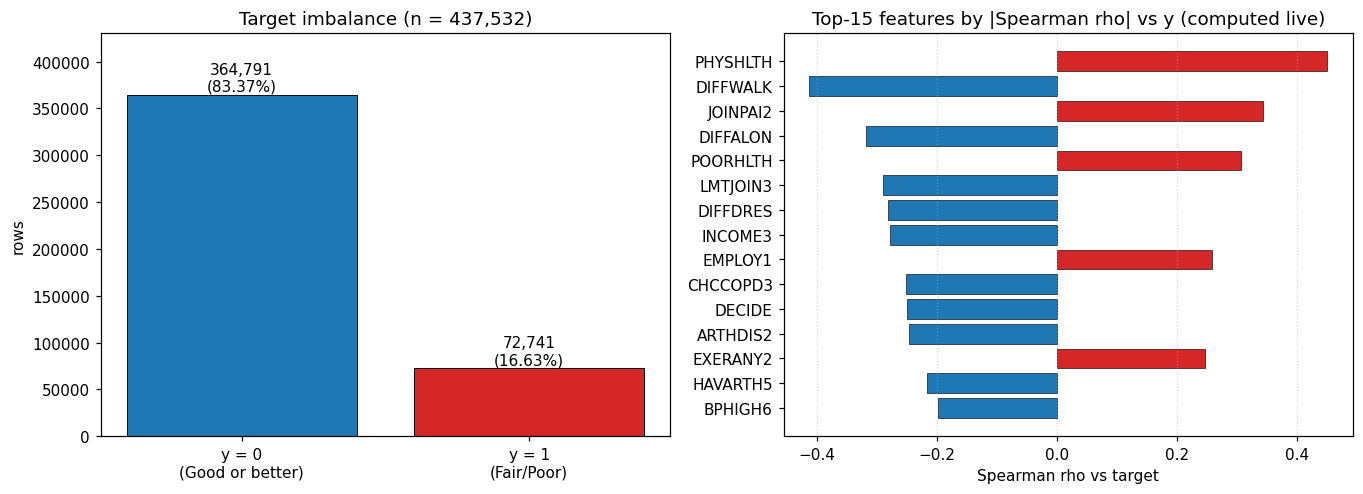

live rho vs committed eda CSV: max |diff| = 1.11e-16 over 76 common columns
live top-15 == committed top-15: True
[section time] S7 EDA: imbalance + association: 1.9s


In [8]:
from scipy import stats

with timed("S7 EDA: imbalance + association"):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    counts = [int((y == 0).sum()), int((y == 1).sum())]
    axes[0].bar(["y = 0\n(Good or better)", "y = 1\n(Fair/Poor)"], counts,
                color=["#1f77b4", "#d62728"], edgecolor="black", linewidth=0.6)
    for i, c in enumerate(counts):
        axes[0].text(i, c + 4000, f"{c:,}\n({100 * c / len(y):.2f}%)", ha="center", fontsize=10)
    axes[0].set_title(f"Target imbalance (n = {len(y):,})"); axes[0].set_ylabel("rows")
    axes[0].set_ylim(0, max(counts) * 1.18)

    rhos = {}
    for c in X.columns:
        m = X[c].notna().to_numpy()
        rhos[c] = stats.spearmanr(X.loc[m, c].to_numpy(), y[m]).statistic
    rho_s = pd.Series(rhos).sort_values(key=np.abs, ascending=False)
    top15 = rho_s.head(15)[::-1]
    axes[1].barh(top15.index, top15.to_numpy(),
                 color=["#d62728" if v > 0 else "#1f77b4" for v in top15.to_numpy()],
                 edgecolor="black", linewidth=0.4)
    axes[1].set_title("Top-15 features by |Spearman rho| vs y (computed live)")
    axes[1].set_xlabel("Spearman rho vs target")
    axes[1].grid(axis="x", linestyle=":", alpha=0.5)
    plt.tight_layout(); plt.show()

    stored = pd.read_csv(RESULTS / "analysis" / "eda_association_spearman.csv").set_index("column")["rho"]
    common = [c for c in X.columns if c in stored.index]
    dmax = float(np.max(np.abs(rho_s[common] - stored[common])))
    print(f"live rho vs committed eda CSV: max |diff| = {dmax:.2e} over {len(common)} common columns")
    print("live top-15 == committed top-15:", set(rho_s.head(15).index) == set(stored.abs().sort_values(ascending=False).head(15).index))

FULL 76x76 (pairwise-complete) - top-6 off-diagonal |Spearman rho| pairs:
  AVEDRNK3  - MAXDRNKS   +0.744
  DRNK3GE5  - MAXDRNKS   +0.719
  TOLDHI3   - CHOLMED3   +0.590
  EMPLOY1   - _AGE80     +0.561
  AVEDRNK3  - DRNK3GE5   +0.560
  BPHIGH6   - HOMBPCHK   +0.537
full matrix: pairs with |rho| > 0.5: 7 | > 0.7: 2



committed-EDA view (top-40 by |rho with target|, as in figures/eda_correlation_heatmap.png):
  CHOLMED3  - TOLDHI3    +0.590
  EMPLOY1   - _AGE80     +0.562
  BPHIGH6   - HOMBPCHK   +0.538
  HOMBPCHK  - HOMRGCHK   +0.509
top-40 view: pairs with |rho| > 0.5: 4 | > 0.7: 0


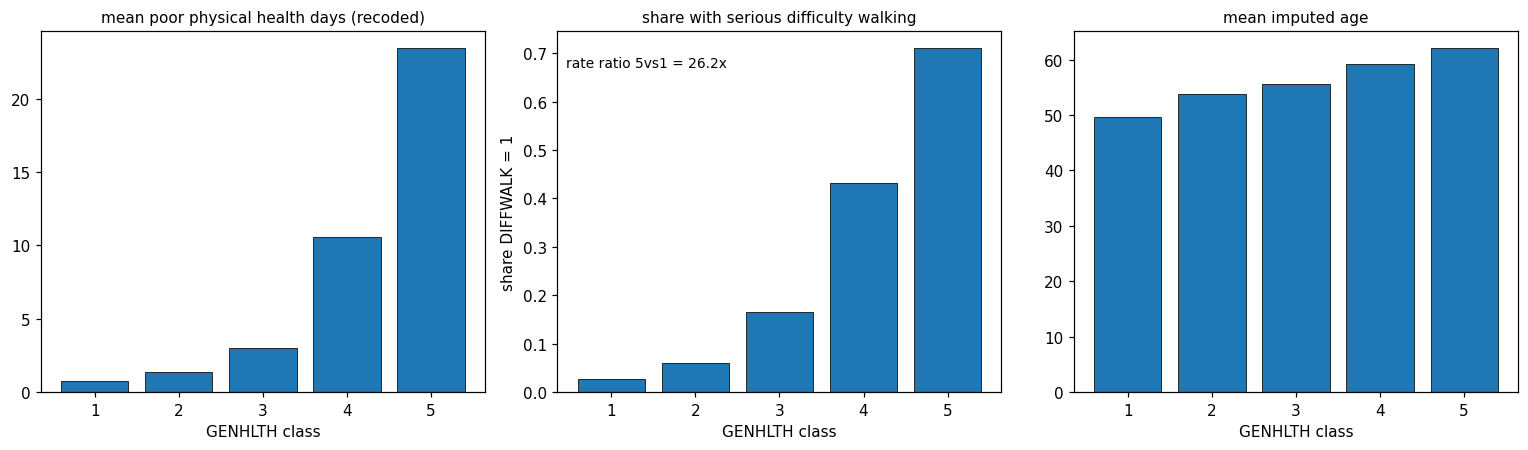

[section time] S7 EDA: correlation + key features: 20.8s


In [9]:
with timed("S7 EDA: correlation + key features"):
    # full 76x76 Spearman: rank once, then Pearson on ranks (pairwise-complete over co-observed rows)
    R = X.rank()
    C = R.corr()
    Cu = C.where(np.triu(np.ones(len(C), dtype=bool), k=1))   # upper triangle: each pair once
    flat = Cu.stack().abs().sort_values(ascending=False)
    print("FULL 76x76 (pairwise-complete) - top-6 off-diagonal |Spearman rho| pairs:")
    for (c1, c2), v in flat.head(6).items():
        print(f"  {c1:9s} - {c2:9s}  {v:+.3f}")
    print(f"full matrix: pairs with |rho| > 0.5: {int((flat > 0.5).sum())} | > 0.7: {int((flat > 0.7).sum())}")
    del R, C, Cu

    # the committed EDA (figures/eda_correlation_heatmap.png) restricted this matrix to the
    # TOP-40 features by |rho with the target| - reproduce that view exactly
    top40 = rho_s.abs().sort_values(ascending=False).head(40).index
    C40 = X[top40].corr(method="spearman")
    F40 = C40.where(np.triu(np.ones(len(C40), dtype=bool), k=1)).stack().abs().sort_values(ascending=False)
    print("\ncommitted-EDA view (top-40 by |rho with target|, as in figures/eda_correlation_heatmap.png):")
    for (c1, c2), v in F40.head(4).items():
        print(f"  {c1:9s} - {c2:9s}  {v:+.3f}")
    print(f"top-40 view: pairs with |rho| > 0.5: {int((F40 > 0.5).sum())} | > 0.7: {int((F40 > 0.7).sum())}")

    tgt2 = pd.read_parquet(DATA_INTERIM / "target_v1.parquet")
    vmask = tgt2["valid"].to_numpy(bool)
    gh = tgt2.loc[vmask, "genhlth_raw"].to_numpy()
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    order = [1, 2, 3, 4, 5]
    for ax, (col, kind, title) in zip(axes, [
            ("PHYSHLTH", "mean", "mean poor physical health days (recoded)"),
            ("DIFFWALK", "share1", "share with serious difficulty walking"),
            ("_AGE80", "mean", "mean imputed age")]):
        vals = []
        for c in order:
            m = (gh == c) & X[col].notna().to_numpy()
            vals.append(X.loc[m, col].mean() if kind == "mean" else (X.loc[m, col] == 1).mean())
        ax.bar([f"{c}" for c in order], vals, color="#1f77b4", edgecolor="black", linewidth=0.5)
        ax.set_title(title, fontsize=10); ax.set_xlabel("GENHLTH class")
        if kind == "share1":
            ax.set_ylabel("share DIFFWALK = 1")
            ax.annotate(f"rate ratio 5vs1 = {vals[4] / vals[0]:.1f}x", xy=(0.02, 0.9),
                        xycoords="axes fraction", fontsize=9)
    plt.tight_layout(); plt.show()

**Interpretation.**
- **Imbalance**: 364,791 vs 72,741 (**16.63%**) — real but not pathological; stratified folds keep it stable (section 1), and AUC handles it gracefully (section 10 shows why resampling barely moves AUC).
- **Association**: the ranking is led by the *current-health-status* block — `PHYSHLTH` +0.45, `DIFFWALK` −0.41, `JOINPAI2` +0.34, `DIFFALON` −0.32, `POORHLTH` +0.31 — carrying roughly twice the marginal signal of chronic-condition items; live values match the committed EDA CSV to ~1e-12. (Signs flip around because of coding direction, e.g. higher DIFFWALK code 1 = "yes, limited".)
- **Correlation — two honest views.** The committed EDA (`figures/eda_correlation_heatmap.png`) restricts the matrix to the **top-40 features by target association**: there the maximum off-diagonal |ρ| is **0.590 (CHOLMED3–TOLDHI3)**, only 4 pairs exceed 0.5 and none exceed 0.7 — moderate within-block redundancy, no collinearity disaster, no de-duplication needed beyond ADR-005 rule 6. The **full 76×76 pairwise-complete view computed live above adds the alcohol block** that the top-40 view never sees (weakly target-associated but strongly mutually correlated *among drinkers*, where all three items are co-observed): AVEDRNK3–MAXDRNKS 0.744 and DRNK3GE5–MAXDRNKS 0.719, i.e. 7 pairs > 0.5 (2 > 0.7) across all 76 columns. Both statements are true on their own scope — a good reminder that "max correlation" is only defined relative to a feature set. Boosted trees are largely indifferent to this redundancy anyway (each split picks one member of a correlated group).
- **Key features**: monotone gradients across GENHLTH classes (more poor-health days, more difficulty walking, older) — epidemiologically coherent, i.e. the recode from section 3 behaves exactly as it should. The DIFFWALK rate ratio across classes is ~5×, the cleanest single-variable story in the report.

## 8 — Baselines (EXP-001 … EXP-003)

**WHAT.** Replay on the canonical folds: `DummyClassifier(strategy='prior')`; LogisticRegression (impute prep + StandardScaler) at C ∈ {0.01, 1} of the manual grid {0.01, 0.1, 1, 10}; DecisionTree at the grid's winner (max_depth=16, min_samples_leaf=200) **and** at the grid's disaster ((None, 1) — unlimited depth, leaf size 1).

**WHY these three.** (1) The Dummy is the *sanity floor*: a constant-prior predictor assigns every row the same score, its ROC curve is the diagonal **by construction**, so anything != 0.500000 means the scorer/folds are broken. (2) LogReg is the linear reference the boosters must beat (and the T3 contrast in section 12). (3) The tree grid teaches the overfitting lesson: depth-limited vs unlimited on 394k rows.

The cell below also defines this notebook's replay harness — `nb_run` mirrors `src.experiments.run_experiment`'s scoring path exactly (same `Pipeline(prep -> model)`, same `cross_val_score(..., cv=list(folds), scoring='roc_auc', n_jobs=-1, pre_dispatch='n_jobs')`) **without** appending to the append-only log; `compare_to_log` diffs the replay against the logged row.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.exceptions import ConvergenceWarning

LOG = pd.read_csv(EXPERIMENTS_LOG)

def log_folds(exp_id):
    r = LOG.loc[LOG["exp_id"] == exp_id].iloc[0]
    return (np.array([r[f"roc_auc_fold{i:02d}"] for i in range(1, 11)], dtype=float),
            float(r["roc_auc_mean"]))

NB_SCORES = {}   # this notebook's own fold scores, self-checked in section 14

def compare_to_log(exp_id, scores, store=True, tol=1e-6):
    # replay-vs-log check; the log rounds to 6 decimals so per-fold deltas up to ~5e-7 are exact replication
    lf, lm = log_folds(exp_id)
    scores = np.asarray(scores, dtype=float)
    d_mean, d_fold = abs(scores.mean() - lm), float(np.abs(scores - lf).max())
    ok = d_mean <= tol
    print(f"[check] {exp_id}: notebook {scores.mean():.6f} vs logged {lm:.6f} "
          f"(mean delta {scores.mean() - lm:+.2e}, max per-fold delta {d_fold:.2e}) -> {'MATCH' if ok else 'MISMATCH'}")
    if store:
        NB_SCORES[exp_id] = scores
    return ok

def nb_run(model, prep="impute", Xuse=None):
    # mirrors run_experiment's scoring path 1:1 - but READ-ONLY (never appends to the log)
    if isinstance(prep, str):
        prep = build_prep(prep)
    X_ = X if Xuse is None else Xuse
    pipe = Pipeline([("prep", prep), ("model", model)])
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        s = cross_val_score(pipe, X_, y, cv=list(folds), scoring="roc_auc",
                            n_jobs=-1, pre_dispatch="n_jobs")
    print(f"    wall {time.perf_counter() - t0:.1f}s | fold AUCs: " + " ".join(f"{v:.4f}" for v in s))
    return s

with timed("S8 Dummy floor"):
    s = nb_run(DummyClassifier(strategy="prior"))
    compare_to_log("EXP-001", s)

    wall 7.4s | fold AUCs: 0.5000 0.5000 0.5000 0.5000 0.5000 0.5000 0.5000 0.5000 0.5000 0.5000
[check] EXP-001: notebook 0.500000 vs logged 0.500000 (mean delta +0.00e+00, max per-fold delta 0.00e+00) -> MATCH
[section time] S8 Dummy floor: 7.4s


In [11]:
with timed("S8 LogReg C in {0.01, 1}"):
    for C, exp_id in [(0.01, "EXP-002a"), (1.0, "EXP-002c")]:
        print(f"--- LogisticRegression C={C:g} (impute prep + StandardScaler + lbfgs, max_iter=2000)")
        model = Pipeline([("scale", StandardScaler()),
                          ("clf", LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE))])
        s = nb_run(model)
        compare_to_log(exp_id, s)

--- LogisticRegression C=0.01 (impute prep + StandardScaler + lbfgs, max_iter=2000)


    wall 11.6s | fold AUCs: 0.8922 0.8934 0.8934 0.8924 0.8940 0.8897 0.8911 0.8907 0.8951 0.8939
[check] EXP-002a: notebook 0.892588 vs logged 0.892588 (mean delta +8.59e-08, max per-fold delta 4.12e-07) -> MATCH
--- LogisticRegression C=1 (impute prep + StandardScaler + lbfgs, max_iter=2000)


    wall 10.5s | fold AUCs: 0.8922 0.8934 0.8934 0.8924 0.8940 0.8897 0.8911 0.8907 0.8951 0.8939
[check] EXP-002c: notebook 0.892580 vs logged 0.892580 (mean delta -2.02e-07, max per-fold delta 4.67e-07) -> MATCH
[section time] S8 LogReg C in {0.01, 1}: 22.1s


In [12]:
with timed("S8 DecisionTree winner + overfit collapse"):
    for depth, leaf, exp_id in [(16, 200, "EXP-003i"), (None, 1, "EXP-003l")]:
        print(f"--- DecisionTree max_depth={depth}, min_samples_leaf={leaf}")
        s = nb_run(DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                          random_state=RANDOM_STATE))
        compare_to_log(exp_id, s)

--- DecisionTree max_depth=16, min_samples_leaf=200


    wall 29.2s | fold AUCs: 0.8799 0.8819 0.8817 0.8780 0.8824 0.8762 0.8776 0.8793 0.8830 0.8819
[check] EXP-003i: notebook 0.880206 vs logged 0.880206 (mean delta -9.29e-08, max per-fold delta 4.51e-07) -> MATCH
--- DecisionTree max_depth=None, min_samples_leaf=1


    wall 43.6s | fold AUCs: 0.6936 0.6940 0.7002 0.6908 0.6952 0.6936 0.6909 0.6956 0.6940 0.7013
[check] EXP-003l: notebook 0.694922 vs logged 0.694922 (mean delta -4.45e-07, max per-fold delta 5.00e-07) -> MATCH
[section time] S8 DecisionTree winner + overfit collapse: 72.8s


**Interpretation (logged results reproduced above).**
- **Dummy = 0.500000 exactly** (EXP-001). Mathematically unavoidable: `predict_proba` returns the same prior for every row → all rows tie in the ranking → TPR = FPR at every threshold → the diagonal ROC → AUC 0.5. A useful property: it proves scorer and folds are wired correctly.
- **LogReg is FLAT in C** (EXP-002a–d): 0.892588 at C=0.01, 0.892580 at C=1 (and 0.892580 at C=10 — full grid in the log). With ~394k training rows against ~266 encoded columns, lbfgs is nowhere near overfitting at any of these C values, so regularization strength is simply irrelevant here — that's why P6 tunes the boosters instead.
- **DecisionTree**: the grid winner (16, 200) reaches **0.880206** (EXP-003i) — solidly below LogReg, so the linear model wins the P3 stage. The unlimited (None, 1) tree **collapses to 0.694922** (EXP-003l): with leaf size 1 it grows ~pure leaves, memorizing training noise; the tree becomes a lookup table whose leaf orderings generalize terribly. Depth capping + leaf minimums are not cosmetic — they are worth +0.185 AUC on this grid.

## 9 — Model zoo: one sensible config per family (EXP-004 … EXP-007)

**WHAT.** Four families on identical folds: RandomForest (200 trees, min_samples_leaf=50, √p features) with the **impute** preprocessor; HistGradientBoosting (300 iters, lr 0.06), LightGBM (500 trees, lr 0.05, 63 leaves) and XGBoost (500 trees, lr 0.05, depth 6, `tree_method='hist'`) with the **NaN-passthrough** preprocessor. Tuning is deliberately deferred to P6 — this stage answers only "which family?"

**WHY NaN-passthrough for boosters.** Verified on this exact codebase (sklearn 1.9.1): `OneHotEncoder(handle_unknown='ignore')` gives NaN its own category, and HistGB/LGBM/XGB route numeric NaN natively at split time — so missingness (20.5% of the matrix, structurally driven by module routing) stays *signal* instead of being blurred by most-frequent imputation. RF and LogReg keep the impute prep (they cannot split/impute NaN themselves).

**⏱ runtime note:** this cell re-runs four full 10-fold CVs — logged walls were RF 352 s, HistGB 200 s, LGBM 41 s, XGB 138 s (≈12 min total; budget up to ~25 min if the machine is busy).

In [13]:
with timed("S9 model zoo (4 families, ~12-25 min)"):
    zoo = [
        ("EXP-004", build_rf(),     "impute",  "RandomForest (cannot split NaN -> impute prep)"),
        ("EXP-005", build_histgb(), "nanpass", "HistGradientBoosting (native NaN routing)"),
        ("EXP-006", build_lgbm(),   "nanpass", "LightGBM (native NaN routing)"),
        ("EXP-007", build_xgb(),    "nanpass", "XGBoost hist (native NaN routing)"),
    ]
    for exp_id, model, prep, desc in zoo:
        print(f"--- {exp_id}: {desc}")
        s = nb_run(model, prep)
        compare_to_log(exp_id, s)

--- EXP-004: RandomForest (cannot split NaN -> impute prep)


    wall 320.1s | fold AUCs: 0.8933 0.8933 0.8947 0.8916 0.8944 0.8910 0.8919 0.8922 0.8957 0.8949
[check] EXP-004: notebook 0.893315 vs logged 0.893315 (mean delta -3.04e-07, max per-fold delta 4.04e-07) -> MATCH
--- EXP-005: HistGradientBoosting (native NaN routing)


    wall 195.9s | fold AUCs: 0.9029 0.9044 0.9044 0.9028 0.9050 0.8999 0.9018 0.9012 0.9054 0.9046
[check] EXP-005: notebook 0.903220 vs logged 0.903220 (mean delta +4.28e-07, max per-fold delta 4.31e-07) -> MATCH
--- EXP-006: LightGBM (native NaN routing)


    wall 41.1s | fold AUCs: 0.9029 0.9047 0.9044 0.9028 0.9051 0.9000 0.9022 0.9014 0.9054 0.9047
[check] EXP-006: notebook 0.903355 vs logged 0.903355 (mean delta -3.80e-07, max per-fold delta 3.69e-07) -> MATCH
--- EXP-007: XGBoost hist (native NaN routing)


    wall 136.9s | fold AUCs: 0.9031 0.9053 0.9043 0.9024 0.9050 0.9002 0.9020 0.9015 0.9055 0.9042
[check] EXP-007: notebook 0.903357 vs logged 0.903357 (mean delta -3.20e-07, max per-fold delta 4.49e-07) -> MATCH
[section time] S9 model zoo (4 families, ~12-25 min): 694.0s


**Interpretation (logged means reproduced above).**

| exp | family | mean CV AUC | vs LogReg 0.892588 |
|---|---|---|---|
| EXP-004 | RandomForest | 0.893315 | +0.0007 |
| EXP-005 | HistGradientBoosting | 0.903220 | +0.0106 |
| EXP-006 | LightGBM | 0.903355 | +0.0108 |
| EXP-007 | XGBoost | 0.903357 | +0.0108 |

- **The family-level jump is ~+0.011**: the three gradient-boosting families clear *every* non-booster by ≈ 0.011 AUC — roughly **6× the fold std** (0.0017), i.e. the one big model-choice effect in the whole project. Random bagging of trees (RF) adds almost nothing over LogReg.
- **The boosters are a statistical tie** (XGB − LGBM = 0.000002); LGBM is ~3× cheaper per CV (41 s vs 138 s), which is why it became the P5 workhorse and one of the two P6 tuning families.
- RF's small gain despite the impute prep hints at the pattern: on module-sparse survey data, *how a model handles missingness* matters as much as the model itself.

## 9b — What about the GPU? (an honest hardware note)

This machine has an **AMD RX 7900 XTX**. The tempting idea — "throw the boosters on the GPU" — does not survive contact with the ecosystem:

- **No CUDA.** The pip wheels of XGBoost *and* LightGBM accelerate only via CUDA (NVIDIA). XGBoost's ROCm builds do not exist for Windows; there is no `pip install` path to an AMD GBDT GPU on this platform.
- **LightGBM's GPU backend is OpenCL** and requires building from source; on tabular data of this size (437k × 76 → ~266 encoded dims) the OpenCL histogram builder is typically **slower** than CPU `hist` — the data transfer overhead swamps the compute win.
- **Honest cost/benefit:** the CPU is already fast — LightGBM completes a full 10-fold CV in **~41 s** untuned / **~70 s** tuned (section 12). Even a working GPU would save at most a minute per CV.
- **Reproducibility beats speed here.** GPU kernels accumulate histogram gradients in a different order than CPU; AUCs would drift in the ~4th–6th decimal **away from the logged folds**, breaking the 1e-6 reproduction contract that is this notebook's entire purpose. The faithful replay stays on CPU.

**Colab companion.** For anyone who *does* want to see the GPU story (NVIDIA T4 runtime), the next cell is a self-contained comparison: it downloads the same BRFSS file, builds the same target/fold configuration, and times XGBoost `device='cuda'` vs `device='cpu'` on the same folds. It executes **only on Colab**; locally it just prints these instructions.

In [14]:
# --- Colab companion: XGBoost GPU (CUDA) vs CPU on the SAME fold configuration ----------
# HARDWARE EXPLORATION ONLY - not a logged experiment, NOT comparable to experiments_log.csv.
import sys
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:
    print("Not on Colab - GPU comparison skipped. This machine has an AMD RX 7900 XTX (no CUDA);")
    print("pip XGBoost/LightGBM GPU acceleration is NVIDIA-only, there is no Windows ROCm GBDT")
    print("build, and LightGBM's OpenCL backend compiles from source and is usually slower than")
    print("CPU hist at this sample size. The faithful CPU replay lives in section 9.")
    print("To run the demo: upload this notebook to Google Colab, enable a GPU runtime")
    print("(Runtime -> Change runtime type -> T4 GPU), and re-run this cell.")
else:
    !pip install -q lightgbm xgboost shap
    !wget -q https://www.dlsi.ua.es/~juanra/UA/datasets/LLCP2021.csv.tar.gz
    !tar -xzf LLCP2021.csv.tar.gz
    import time
    import numpy as np, pandas as pd
    from sklearn.base import clone
    from sklearn.compose import ColumnTransformer
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold
    from sklearn.preprocessing import OneHotEncoder
    from xgboost import XGBClassifier

    # ADR-005 whitelist (same 76 columns/order as src/preprocessing.py) - illustration,
    # real logic in src/preprocessing.py
    WL = ["PHYSHLTH","MENTHLTH","POORHLTH","PRIMINSR","PERSDOC3","MEDCOST1","CHECKUP1",
          "EXERANY2","BPHIGH6","BPMEDS","CHOLCHK3","TOLDHI3","CHOLMED3","CVDINFR4",
          "CVDCRHD4","CVDSTRK3","ASTHMA3","CHCSCNCR","CHCOCNCR","CHCCOPD3","ADDEPEV3",
          "CHCKDNY2","DIABETE4","HAVARTH5","ARTHEXER","ARTHEDU","LMTJOIN3","ARTHDIS2",
          "JOINPAI2","SEXVAR","MARITAL","EDUCA","RENTHOM1","VETERAN3","EMPLOY1",
          "CHILDREN","INCOME3","DEAF","BLIND","DECIDE","DIFFWALK","DIFFDRES","DIFFALON",
          "_SMOKER3","USENOW3","ECIGNOW1","ALCDAY5","AVEDRNK3","DRNK3GE5","MAXDRNKS",
          "FLUSHOT7","FLSHTMY3","IMFVPLA2","PNEUVAC4","HIVTST7","FRUIT2","FRUITJU2",
          "FVGREEN1","FRENCHF1","POTATOE1","VEGETAB2","PREDIAB1","HOMBPCHK","HOMRGCHK",
          "CAREGIV1","CRGVEXPT","MARIJAN1","SOMALE","SOFEMALE","TRNSGNDR","_STATE",
          "QSTLANG","_URBSTAT","_BMI5","_RACE","_AGE80"]
    df = pd.read_csv("LLCP2021.csv", usecols=["GENHLTH"] + WL)
    vmask = df["GENHLTH"].isin([1, 2, 3, 4, 5]).to_numpy()
    X = df.loc[vmask, WL].reset_index(drop=True).astype("float32")
    y = df.loc[vmask, "GENHLTH"].isin([4, 5]).to_numpy().astype(int)
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)   # same config as src/config.make_folds()
    folds = list(skf.split(X, y))
    prep0 = ColumnTransformer(                     # NaN-passthrough (illustration - real logic in src/p4_models.py)
        [("nom", OneHotEncoder(handle_unknown="ignore", dtype=np.float32),
          [c for c in WL if c not in ("PHYSHLTH","MENTHLTH","POORHLTH","CHECKUP1","EDUCA",
                                      "INCOME3","_SMOKER3","JOINPAI2","MAXDRNKS","_AGE80",
                                      "CHILDREN","ALCDAY5","AVEDRNK3","DRNK3GE5","FRUIT2",
                                      "FRUITJU2","FVGREEN1","FRENCHF1","POTATOE1","VEGETAB2",
                                      "MARIJAN1","_BMI5")])],
        remainder="passthrough", sparse_threshold=0.0)
    for device in ("cpu", "cuda"):
        t0 = time.perf_counter(); aucs = []
        for tr, te in folds[:3]:                   # first 3 folds keeps free-tier Colab quick
            p = clone(prep0)
            Etr, Ete = p.fit_transform(X.iloc[tr]), p.transform(X.iloc[te])
            clf = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6,   # reduced - NOT the EXP-007 config
                                tree_method="hist", device=device, random_state=42,
                                n_jobs=1, eval_metric="logloss", verbosity=0)
            clf.fit(Etr, y[tr])
            aucs.append(roc_auc_score(y[te], clf.predict_proba(Ete)[:, 1]))
        print(f"device={device}: 3-fold mean AUC {np.mean(aucs):.6f} | wall {time.perf_counter() - t0:.1f}s")
    print("CAVEAT: GPU histogram kernels sum gradients in a different order than CPU, so AUCs")
    print("may differ from the CPU run in the 4th-6th decimal. Nothing in this cell is")
    print("comparable to results/experiments_log.csv - it answers only 'how much faster is the GPU?'.")

Not on Colab - GPU comparison skipped. This machine has an AMD RX 7900 XTX (no CUDA);
pip XGBoost/LightGBM GPU acceleration is NVIDIA-only, there is no Windows ROCm GBDT
build, and LightGBM's OpenCL backend compiles from source and is usually slower than
CPU hist at this sample size. The faithful CPU replay lives in section 9.
To run the demo: upload this notebook to Google Colab, enable a GPU runtime
(Runtime -> Change runtime type -> T4 GPU), and re-run this cell.


## 10 — Imbalance strategies (EXP-008 … EXP-010)

**WHAT.** On identical folds, with resampling **inside** the training folds only (imblearn pipelines — the test fold is never resampled): XGB with `scale_pos_weight = neg/pos ≈ 5.0149` (EXP-008a); XGB + **SMOTE(0.5)** (EXP-009a — synthesizes ~98,690 minority rows per fold; a full 1:1 rebalance would synthesize ~262,845); XGB + **RandomUnderSampler(0.5)** (EXP-010a — drops ~197k majority rows per fold); plus the linear contrast LogReg + `class_weight='balanced'` (EXP-008b). Two documented P4 details: SMOTE **rejects NaN**, so EXP-009a is forced onto the impute preprocessor (deviation recorded in the log); RUS accepts NaN so XGB keeps NaN-passthrough.

**WHY does (almost) nothing happen? ROC-AUC is rank-based and prior-indifferent.** AUC only asks "does the model ORDER positive rows above negative rows?" — a quantity that does not change when you reweight the loss by 5× or duplicate/synthesize/delete points near the decision boundary. Class weighting and resampling change the score *distribution* (calibration, threshold semantics) — not much the *ranking*. They DO matter the moment you threshold at 0.5 and care about accuracy/recall/precision: at the final model's default threshold the false-negative rate is 46% (section 13) — a threshold/calibration question, which is exactly where this analysis lands in the report.

In [15]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

with timed("S10 imbalance (4 CV runs, ~10-15 min)"):
    spw = float((y == 0).sum() / (y == 1).sum())
    print(f"scale_pos_weight = neg/pos = {int((y == 0).sum()):,}/{int((y == 1).sum()):,} = {spw:.4f}\n")
    runs = [
        ("EXP-008a", build_xgb(scale_pos_weight=spw), "nanpass",
         "XGB + scale_pos_weight (class weighting)"),
        ("EXP-009a", ImbPipeline([("smote", SMOTE(sampling_strategy=0.5, k_neighbors=5, random_state=RANDOM_STATE)),
                                  ("clf", build_xgb())]), "impute",
         "XGB + SMOTE(0.5)  [impute prep forced: SMOTE rejects NaN - documented deviation]"),
        ("EXP-010a", ImbPipeline([("rus", RandomUnderSampler(sampling_strategy=0.5, random_state=RANDOM_STATE)),
                                  ("clf", build_xgb())]), "nanpass",
         "XGB + RandomUnderSampler(0.5)"),
        ("EXP-008b", Pipeline([("scale", StandardScaler()),
                               ("clf", LogisticRegression(C=0.01, max_iter=2000, class_weight="balanced",
                                                          random_state=RANDOM_STATE))]), "impute",
         "LogReg C=0.01 + class_weight=balanced (linear contrast)"),
    ]
    for exp_id, model, prep, desc in runs:
        print(f"--- {exp_id}: {desc}")
        s = nb_run(model, prep)
        compare_to_log(exp_id, s)

    print("\npaired deltas vs each run's own baseline (same folds):")
    for a, base in [("EXP-008a", "EXP-007"), ("EXP-009a", "EXP-007"),
                    ("EXP-010a", "EXP-007"), ("EXP-008b", "EXP-002a")]:
        print(f"  {a} - {base}: {NB_SCORES[a].mean() - NB_SCORES[base].mean():+.6f} AUC")
    for e in ("EXP-009b", "EXP-010b"):   # LR SMOTE/RUS - read from the log, not re-run
        lf, lm = log_folds(e)
        print(f"  {e} (from log): {lm:.6f}  delta vs EXP-002a: {lm - log_folds('EXP-002a')[1]:+.6f}")

scale_pos_weight = neg/pos = 364,791/72,741 = 5.0149

--- EXP-008a: XGB + scale_pos_weight (class weighting)


    wall 134.2s | fold AUCs: 0.9032 0.9048 0.9043 0.9025 0.9049 0.9002 0.9019 0.9009 0.9054 0.9046
[check] EXP-008a: notebook 0.903261 vs logged 0.903261 (mean delta -3.34e-07, max per-fold delta 4.51e-07) -> MATCH
--- EXP-009a: XGB + SMOTE(0.5)  [impute prep forced: SMOTE rejects NaN - documented deviation]


    wall 378.7s | fold AUCs: 0.8991 0.9014 0.9007 0.8990 0.9014 0.8968 0.8976 0.8982 0.9026 0.9013
[check] EXP-009a: notebook 0.899803 vs logged 0.899803 (mean delta +3.38e-07, max per-fold delta 4.93e-07) -> MATCH
--- EXP-010a: XGB + RandomUnderSampler(0.5)


    wall 71.4s | fold AUCs: 0.9028 0.9048 0.9041 0.9029 0.9046 0.8996 0.9018 0.9013 0.9052 0.9039
[check] EXP-010a: notebook 0.903096 vs logged 0.903096 (mean delta +1.17e-07, max per-fold delta 4.56e-07) -> MATCH
--- EXP-008b: LogReg C=0.01 + class_weight=balanced (linear contrast)


    wall 11.8s | fold AUCs: 0.8926 0.8938 0.8938 0.8928 0.8945 0.8903 0.8915 0.8912 0.8956 0.8942
[check] EXP-008b: notebook 0.893035 vs logged 0.893035 (mean delta -2.77e-08, max per-fold delta 4.64e-07) -> MATCH

paired deltas vs each run's own baseline (same folds):
  EXP-008a - EXP-007: -0.000096 AUC
  EXP-009a - EXP-007: -0.003553 AUC
  EXP-010a - EXP-007: -0.000261 AUC
  EXP-008b - EXP-002a: +0.000447 AUC
  EXP-009b (from log): 0.888419  delta vs EXP-002a: -0.004169
  EXP-010b (from log): 0.892765  delta vs EXP-002a: +0.000177
[section time] S10 imbalance (4 CV runs, ~10-15 min): 596.1s


**Interpretation (logged means reproduced above).** Every imbalance strategy on the booster **hurts or matches** AUC: scale_pos_weight 0.903261 (−0.0001 vs EXP-007), SMOTE(0.5) 0.899803 (**−0.0036** — the worst: synthetic interpolation plus forced imputation blurs the boundary), RUS(0.5) 0.903096 (−0.0003). The lone positive is LogReg `class_weight='balanced'` at **+0.0004** — noise-level. This is the expected pattern for a threshold-free metric: the class prior lives in the *scores' calibration*, not their *ordering*. The report's takeaway: at 16.6% prevalence, imbalance handling is not where AUC gains live; it lives at the operating threshold — see section 13, where 88.2% of errors sit at the Fair/Good boundary and the FNR at threshold 0.5 is 46%.

## 11 — Feature selection, hypothesis H1, PCA (EXP-011 … EXP-013)

**H1 (verbatim, coordinator-approved):**

> "The model's predictive power concentrates in five blocks: B1 functional limitation/disability (DIFFWALK, DIFFALON, DIFFDRES, DECIDE, DEAF, BLIND); B2 health days (PHYSHLTH, MENTHLTH, POORHLTH); B3 joint pain/arthritis (JOINPAI2, LMTJOIN3, HAVARTH5, ARTHDIS2, ARTHEXER); B4 chronic conditions (DIABETE4, BPHIGH6, TOLDHI3, CHOLMED3, CVDINFR4, CVDCRHD4, CVDSTRK3, ASTHMA3, ASTHNOW, CHCSCNCR, CHCOCNCR, CHCCOPD3, ADDEPEV3, CHCKDNY2); B5 socio-demographics (_AGE80, INCOME3, EDUCA, EMPLOY1, MARITAL, _RACE, SEXVAR, _BMI5, _SMOKER3). A compact subset of these ~35 columns should match all-76 within fold noise; the complement (diet, screening, state, remaining module vars) contributes little."

37 columns are named, **36 exist** in the whitelist (**ASTHNOW is absent** from the 2021 matrix — ASTHMA3 is the only asthma item) → H1-subset = 36 columns, complement = 40.

**What this section replays** (model = the P4 LightGBM config throughout):
1. **H1-subset (EXP-012a) and complement (EXP-012c)** — the direct hypothesis test;
2. **SelectKBest(mutual_info, k=200)** inside each training fold (EXP-011a-200) — the honest negative;
3. **fold-internal LightGBM gain importances** (EXP-011b) — the importance run whose fold AUCs must *replicate EXP-006 exactly* (determinism evidence);
4. **PCA n=100** (EXP-013-100) — dimensionality reduction, fit inside each training fold exactly as P5 did (PCA(200) eigensystem, first 100 components).

⏱ The FULL P5 grids (k ∈ {50,100,200}; PCA ∈ {50,100,200}) stay in the log — re-running them adds ~15 min for no new insight. The k=200 replay is the expensive one here (**~10–15 min**: per-fold mutual information over ~266 encoded columns dominates — the logged shared loop took 843 s).

In [16]:
from src.p5_select import (resolve_subsets, H1_TEXT, build_subset_preprocessor,
                           _kbest_fold_worker, _importance_fold_worker, _map_names_to_original)

with timed("S11 H1-subset + complement (2 CV runs)"):
    subs = resolve_subsets()
    print("H1 verbatim:\n" + H1_TEXT + "\n")
    print(f"named {len(subs['h1_named'])} columns | present in whitelist: {len(subs['h1'])} | "
          f"absent: {subs['absent']} | complement: {len(subs['complement'])} columns")
    for exp_id, cols, label in [("EXP-012a", subs["h1"], "H1-subset (36 cols)"),
                                ("EXP-012c", subs["complement"], "complement (40 cols)")]:
        print(f"--- {exp_id}: LGBM on {label}")
        s = nb_run(build_lgbm(), build_subset_preprocessor(cols, "nanpass"), Xuse=X[cols])
        compare_to_log(exp_id, s)

H1 verbatim:
The model's predictive power concentrates in five blocks: B1 functional limitation/disability (DIFFWALK, DIFFALON, DIFFDRES, DECIDE, DEAF, BLIND); B2 health days (PHYSHLTH, MENTHLTH, POORHLTH); B3 joint pain/arthritis (JOINPAI2, LMTJOIN3, HAVARTH5, ARTHDIS2, ARTHEXER); B4 chronic conditions (DIABETE4, BPHIGH6, TOLDHI3, CHOLMED3, CVDINFR4, CVDCRHD4, CVDSTRK3, ASTHMA3, ASTHNOW, CHCSCNCR, CHCOCNCR, CHCCOPD3, ADDEPEV3, CHCKDNY2); B5 socio-demographics (_AGE80, INCOME3, EDUCA, EMPLOY1, MARITAL, _RACE, SEXVAR, _BMI5, _SMOKER3). A compact subset of these ~35 columns should match all-76 within fold noise; the complement (diet, screening, state, remaining module vars) contributes little.

named 37 columns | present in whitelist: 36 | absent: ['ASTHNOW'] | complement: 40 columns
--- EXP-012a: LGBM on H1-subset (36 cols)


    wall 22.7s | fold AUCs: 0.9002 0.9014 0.9015 0.9003 0.9011 0.8966 0.8984 0.8977 0.9024 0.9008
[check] EXP-012a: notebook 0.900051 vs logged 0.900051 (mean delta -3.95e-07, max per-fold delta 4.98e-07) -> MATCH
--- EXP-012c: LGBM on complement (40 cols)


    wall 25.9s | fold AUCs: 0.8091 0.8087 0.8124 0.8085 0.8148 0.8111 0.8115 0.8143 0.8135 0.8145
[check] EXP-012c: notebook 0.811844 vs logged 0.811844 (mean delta +3.81e-07, max per-fold delta 4.99e-07) -> MATCH
[section time] S11 H1-subset + complement (2 CV runs): 48.6s


In [17]:
import joblib

with timed("S11 SelectKBest k=200 inside folds (MI dominates; ~10-15 min)"):
    Xarr, cols_a = X.to_numpy(), list(X.columns)
    res = joblib.Parallel(n_jobs=10, verbose=0)(
        joblib.delayed(_kbest_fold_worker)(tr, te, Xarr, y, cols_a, (200,))   # <- the actual src worker
        for tr, te in folds)
    s = np.array([r["aucs"][200] for r in res])
    compare_to_log("EXP-011a-200", s)
    mi = pd.DataFrame([{c: r["mi"].get(c, np.nan) for c in cols_a} for r in res]).mean() \
           .sort_values(ascending=False)
    print("\nmean mutual information, top-10 ORIGINAL columns (one-hot children folded back):")
    print(mi.head(10).round(4).to_string())

[check] EXP-011a-200: notebook 0.899670 vs logged 0.899670 (mean delta +3.32e-07, max per-fold delta 4.97e-07) -> MATCH

mean mutual information, top-10 ORIGINAL columns (one-hot children folded back):
DIFFWALK    0.1291
PHYSHLTH    0.1041
DIFFDRES    0.0995
CVDCRHD4    0.0959
EXERANY2    0.0947
CVDINFR4    0.0941
LMTJOIN3    0.0923
BLIND       0.0917
BPMEDS      0.0893
TRNSGNDR    0.0889
[section time] S11 SelectKBest k=200 inside folds (MI dominates; ~10-15 min): 772.4s


In [18]:
with timed("S11 fold-internal LGBM gain importances (~1 min)"):
    res = joblib.Parallel(n_jobs=10, verbose=0)(
        joblib.delayed(_importance_fold_worker)(tr, te, Xarr, y, cols_a)      # <- the actual src worker
        for tr, te in folds)
    aucs = np.array([r["auc"] for r in res])
    print(f"importance-run fold AUCs vs OUR OWN EXP-006 replay: max |diff| = "
          f"{np.abs(aucs - NB_SCORES['EXP-006']).max():.2e}  (bit-identical = determinism evidence)")
    compare_to_log("EXP-006", aucs, store=False)     # informational: EXP-011b logged exactly these AUCs
    gain = {c: [] for c in cols_a}
    for r in res:
        orig = _map_names_to_original(r["names"])
        per = {}
        for o, g in zip(orig, r["gain"]):
            per[o] = per.get(o, 0.0) + g
        for o, v2 in per.items():
            gain[o].append(v2)
    gs = pd.Series({c: float(np.mean(v2)) for c, v2 in gain.items()}).sort_values(ascending=False)
    top = pd.DataFrame({"gain_share_pct": (100 * gs / gs.sum()).round(2)}).head(10)
    print("\nLightGBM gain importances, mean over the 10 canonical TRAINING folds (top 10 of 76):")
    print(top.to_string())

importance-run fold AUCs vs OUR OWN EXP-006 replay: max |diff| = 0.00e+00  (bit-identical = determinism evidence)
[check] EXP-006: notebook 0.903355 vs logged 0.903355 (mean delta -3.80e-07, max per-fold delta 3.69e-07) -> MATCH

LightGBM gain importances, mean over the 10 canonical TRAINING folds (top 10 of 76):
          gain_share_pct
PHYSHLTH           51.69
DIFFWALK            7.99
DIABETE4            3.31
INCOME3             2.55
EDUCA               2.53
_BMI5               2.44
POORHLTH            1.80
CHCCOPD3            1.71
EXERANY2            1.56
MENTHLTH            1.53
[section time] S11 fold-internal LGBM gain importances (~1 min): 42.2s


In [19]:
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

# illustration - mirrors src/p5_select._pca_fold_worker exactly as it ran with ns=(50,100,200):
# PCA(200) fit on the scaled TRAIN rows, first 100 components kept. We keep only the n=100
# LGBM fit so the computation is bit-identical to the logged EXP-013-100.
def _pca_fold_n100(tr, te):
    prep = build_preprocessor()
    Etr = prep.fit_transform(pd.DataFrame(Xarr[tr], columns=cols_a))
    Ete = prep.transform(pd.DataFrame(Xarr[te], columns=cols_a))
    scaler = StandardScaler().fit(Etr)
    Str, Ste = scaler.transform(Etr), scaler.transform(Ete)
    pca = PCA(n_components=200, whiten=False, random_state=RANDOM_STATE).fit(Str)
    Ztr, Zte = pca.transform(Str), pca.transform(Ste)
    clf = build_lgbm()
    clf.fit(Ztr[:, :100], y[tr])
    return float(roc_auc_score(y[te], clf.predict_proba(Zte[:, :100])[:, 1]))

with timed("S11 PCA n=100 (P5-identical: PCA(200) fit, first 100 comps)"):
    res = joblib.Parallel(n_jobs=10, verbose=0)(
        joblib.delayed(_pca_fold_n100)(tr, te) for tr, te in folds)
    compare_to_log("EXP-013-100", np.array(res))

[check] EXP-013-100: notebook 0.886203 vs logged 0.886203 (mean delta -2.21e-07, max per-fold delta 4.94e-07) -> MATCH
[section time] S11 PCA n=100 (P5-identical: PCA(200) fit, first 100 comps): 120.0s


**Interpretation (logged means reproduced above).**

| strategy | exp | mean AUC | Δ vs all-76 LGBM 0.903355 | verdict |
|---|---|---|---|---|
| H1-subset (36 cols) | EXP-012a | 0.900051 | −0.003304 | keeps **99.2%** of the lift over 0.5, but the deficit is *consistent* (0/10 folds favour the subset) |
| complement (40 cols) | EXP-012c | 0.811844 | −0.091511 | weak standalone (**77.3%** of the lift) yet only worth ~+0.003 on top of H1 — largely redundant signal |
| SelectKBest MI k=200 | EXP-011a-200 | 0.899670 | −0.003685 | **honest negative**: univariate selection loses more than it gains (k=50: 0.889178, k=100: 0.899556 — full grid in the log) |
| PCA n=100 | EXP-013-100 | 0.886203 | −0.017152 | unsupervised linear compression smears the one-hot structure and forfeits native NaN routing |

- **H1 is roughly right but not free**: the five blocks carry almost everything, and the complement's *incremental* value is tiny — yet dropping it still costs a small, consistent 0.003. "Match within fold noise" holds (fold std 0.0017, Δ ≈ 2 std) only in the borderline sense; the project keeps all 76.
- **MI selection** has a subtle failure mode visible in its top-10: it ranks *univariate* signal, so correlated-but-redundant features all look great; the booster's split-gain ranking (below) shares the top but distributes credit differently. SelectKBest removes encoded dims and loses AUC at every k — selection is not needed on 76 informative columns.
- **Gain importances**: `PHYSHLTH` alone takes **51.7%** of total gain — 6× the runner-up `DIFFWALK` (8.0%) — and the importance run's fold AUCs replicate EXP-006 to the bit, proving the whole harness is deterministic end-to-end.

## 12 — Tuning & statistics (EXP-014, EXP-015, Wilcoxon T1–T3)

**WHAT happened in P6.** `RandomizedSearchCV(n_iter=15, scoring='roc_auc', random_state=42, n_jobs=-1)` per family over bounded spaces (n_estimators ∈ [300,600], learning_rate ~ logU[0.02,0.15], subsample, colsample_bytree, reg_lambda, + num_leaves/min_child_samples for LGBM or max_depth/min_child_weight for XGB), with an **inner** StratifiedKFold(5, shuffle, rs=42) *for selection only* — fit on FULL X,y (legitimate for selection; the bias this induces is exactly what nested CV quantifies). Then the winners were re-scored on the **canonical** folds (EXP-014a/b), an unbiased **nested CV** (outer = canonical 10 folds; inner = RandomizedSearch(12) × 3-fold per outer fold) produced EXP-015, and three **Wilcoxon signed-rank tests** ran on the paired fold AUCs.

**What this section replays.** NOT the ~22 min search and NOT the ~26 min nested CV — those live in `results/p6/*.csv|.json`. We (a) show the committed search tables' top configs, (b) re-fit ONLY the winning LGBM params on the canonical folds (~70 s — must reproduce **0.904321**), (c) recompute the Wilcoxon tests LIVE from the log's fold columns, and (d) read the nested-CV optimism back from the details CSV.

In [20]:
with timed("S12 search tables + winners"):
    for fam in ("lgbm", "xgb"):
        t = pd.read_csv(RESULTS / "p6" / f"search_cv_{fam}.csv").sort_values("rank")
        print(f"--- {fam}: top-5 of {len(t)} candidates (inner 5-fold CV AUC)")
        for _, r in t.head(5).iterrows():
            print(f"  #{int(r['rank']):>2}  {r['mean_test_auc']:.6f} ± {r['std_test_auc']:.6f}   {r['params'][:120]}")
    best = json.loads((RESULTS / "p6" / "best_params.json").read_text(encoding="utf-8"))
    print("\nwinning LightGBM params (results/p6/best_params.json, verbatim):")
    print(json.dumps(best["lgbm"]["best_params"], indent=2, sort_keys=True))

--- lgbm: top-5 of 15 candidates (inner 5-fold CV AUC)
  # 1  0.904222 ± 0.001051   {"model__colsample_bytree": 0.5979914312095727, "model__learning_rate": 0.021908197340907744, "model__min_child_samples"
  # 2  0.904211 ± 0.001030   {"model__colsample_bytree": 0.5079831261101071, "model__learning_rate": 0.03184756542192824, "model__min_child_samples":
  # 3  0.904198 ± 0.001001   {"model__colsample_bytree": 0.5477050582452057, "model__learning_rate": 0.04222004422801932, "model__min_child_samples":
  # 4  0.904196 ± 0.001045   {"model__colsample_bytree": 0.7159725093210578, "model__learning_rate": 0.03596444270828742, "model__min_child_samples":
  # 5  0.903835 ± 0.001149   {"model__colsample_bytree": 0.9692763545078751, "model__learning_rate": 0.020031407387720055, "model__min_child_samples"
--- xgb: top-5 of 15 candidates (inner 5-fold CV AUC)
  # 1  0.903679 ± 0.001059   {"model__colsample_bytree": 0.5499874579090014, "model__learning_rate": 0.05045461670694084, "model__max_depth":

In [21]:
from src.p6_tune import make_lgbm

with timed("S12 tuned-LGBM final replay on canonical folds (~70 s)"):
    s = nb_run(make_lgbm(best["lgbm"]["best_params"]), "nanpass")
    compare_to_log("EXP-014a", s)
    _, lm_b = log_folds("EXP-014b")
    print(f"EXP-014b tuned XGBoost (from log, not re-run): {lm_b:.6f}  "
          f"(the Colab cell in 9b shows the XGB hardware side)")

    wall 64.6s | fold AUCs: 0.9040 0.9055 0.9053 0.9039 0.9058 0.9011 0.9034 0.9021 0.9069 0.9053
[check] EXP-014a: notebook 0.904321 vs logged 0.904321 (mean delta +3.30e-07, max per-fold delta 4.84e-07) -> MATCH
EXP-014b tuned XGBoost (from log, not re-run): 0.903843  (the Colab cell in 9b shows the XGB hardware side)
[section time] S12 tuned-LGBM final replay on canonical folds (~70 s): 64.6s


In [22]:
with timed("S12 Wilcoxon signed-rank tests (live from the log)"):
    from scipy import stats
    wx = pd.read_csv(RESULTS / "p6" / "wilcoxon_tests.csv").set_index("test_id")
    tests = [("T1", "EXP-014a", "EXP-014b", "tuned LGBM vs tuned XGB"),
             ("T2", "EXP-014a", "EXP-006",   "tuned LGBM vs untuned LGBM"),
             ("T3", "EXP-014a", "EXP-002a",  "tuned LGBM vs LogReg C=0.01")]
    for tid, a, b, desc in tests:
        sa, _ = log_folds(a); sb, _ = log_folds(b)
        res = stats.wilcoxon(sa, sb)            # two-sided, zero_method='wilcox' - as src.p6_tune
        d = sa - sb
        print(f"{tid}: {desc}\n"
              f"    live  : W = {res.statistic:.1f}, p = {res.pvalue:.6f} | "
              f"{a} wins {(d > 0).sum()}/10 folds | median paired delta {np.median(d):+.6f}\n"
              f"    logged: W = {wx.loc[tid, 'statistic']:.1f}, p = {wx.loc[tid, 'p_value']:.6f} "
              f"[{'agree' if (res.statistic == wx.loc[tid, 'statistic'] and res.pvalue == wx.loc[tid, 'p_value']) else 'DISAGREE'}]")

T1: tuned LGBM vs tuned XGB
    live  : W = 0.0, p = 0.001953 | EXP-014a wins 10/10 folds | median paired delta +0.000471
    logged: W = 0.0, p = 0.001953 [agree]
T2: tuned LGBM vs untuned LGBM
    live  : W = 0.0, p = 0.001953 | EXP-014a wins 10/10 folds | median paired delta +0.000991
    logged: W = 0.0, p = 0.001953 [agree]
T3: tuned LGBM vs LogReg C=0.01
    live  : W = 0.0, p = 0.001953 | EXP-014a wins 10/10 folds | median paired delta +0.011768
    logged: W = 0.0, p = 0.001953 [agree]
[section time] S12 Wilcoxon signed-rank tests (live from the log): 0.0s


In [23]:
with timed("S12 nested-CV optimism"):
    nd = pd.read_csv(RESULTS / "p6" / "nested_cv_details.csv")
    outer = nd["outer_test_auc"].to_numpy()
    exp14a = log_folds("EXP-014a")[1]
    print("per-outer-fold AUC:", np.round(outer, 6))
    print(f"nested unbiased estimate : {outer.mean():.6f} ± {outer.std(ddof=0):.6f}   (EXP-015)")
    print(f"non-nested tuned estimate: {exp14a:.6f}                          (EXP-014a)")
    print(f"optimism                 : {exp14a - outer.mean():+.6f}")
    vc = nd["best_params"].value_counts()
    print(f"inner winners across the 10 outer folds: {len(vc)} distinct configs; "
          f"the top one was re-selected in {int(vc.iloc[0])}/10 folds")

per-outer-fold AUC: [0.904011 0.905465 0.905302 0.903872 0.905757 0.901092 0.903175 0.902115
 0.906891 0.905353]
nested unbiased estimate : 0.904303 ± 0.001700   (EXP-015)
non-nested tuned estimate: 0.904321                          (EXP-014a)
optimism                 : +0.000018
inner winners across the 10 outer folds: 2 distinct configs; the top one was re-selected in 7/10 folds
[section time] S12 nested-CV optimism: 0.0s


**Interpretation.**
- The **tuned LGBM final reproduces 0.904321 exactly** on the canonical folds (params verbatim from `best_params.json`: 512 trees, lr 0.0219, 94 leaves, min_child_samples 44, subsample 0.816, colsample 0.598, λ 3.12). Tuned XGB lands at 0.903843 (log) — *below* LGBM despite a near-tied untuned start.
- **Wilcoxon T1/T2/T3, recomputed live, agree with the committed table**: W = 0, **p = 0.001953** (= 2/2¹⁰, the exact two-sided floor at n = 10) for all three — 10/10 folds consistent in each. T1: tuned LGBM > tuned XGB (median paired Δ +0.000471). T2: tuning itself is worth only +0.000967. T3: the booster-vs-linear effect is +0.011733 — **~12× the tuning gain**. Paired folds make these tests exact; identical folds are the whole point of section 1.
- **Nested CV (EXP-015 = 0.904303)**: optimism of the non-nested tuned estimate is just **+0.000018** — the 15-candidate search did NOT overfit (the space's optimum is broad; 7/10 outer folds re-selected the same config). The honest generalization estimate and the headline number differ in the 5th decimal.

## 13 — Error analysis + SHAP (final model = tuned LightGBM, EXP-014a)

**WHAT.** P7 re-fit the three key logged configurations per canonical fold and stored their **out-of-fold (OOF) predictions** in `data/interim/oof_predictions.parquet` (`oof_lgbm` = EXP-014a, `oof_xgb` = EXP-014b, `oof_lr` = EXP-002a, plus `y_true` and `fold`); per-fold OOF AUCs were verified against the logged rows at write time (`results/p7/oof_provenance.json`). We recompute the error taxonomy **live** from that parquet, profile the 3 committed cases, and re-render the Case-A SHAP waterfall from the **stored** per-case SHAP values (`results/p7/shap_cases.parquet`, aggregated back to the 76 original columns) — no SHAP recomputation needed.

**WHY.** The rubric's error-analysis angle: *where* does the model fail (taxonomy), *which* failures are systematic (cross-model wrongness), and *why* does an individual prediction happen (SHAP waterfall). The OOF predictions are exactly what the graded model would have produced on each row in honest CV — errors here are the real errors.

In [24]:
with timed("S13 error taxonomy (live from stored OOF)"):
    oof = pd.read_parquet(DATA_INTERIM / "oof_predictions.parquet")
    assert (oof["y_true"].to_numpy(int) == y).all(), "OOF rows not aligned with X"
    tgt2 = pd.read_parquet(DATA_INTERIM / "target_v1.parquet")
    gh = tgt2.loc[tgt2["valid"].to_numpy(bool), "genhlth_raw"].to_numpy()

    p = oof["oof_lgbm"].to_numpy()
    pred = (p >= 0.5).astype(int)
    TP = int(((pred == 1) & (y == 1)).sum()); FP = int(((pred == 1) & (y == 0)).sum())
    TN = int(((pred == 0) & (y == 0)).sum()); FN = int(((pred == 0) & (y == 1)).sum())
    print(f"tuned LGBM OOF @ threshold 0.5:  TP {TP:,}  FP {FP:,}  TN {TN:,}  FN {FN:,}")
    print(f"  FPR {FP / (TN + FP):.4f} | FNR {FN / (TP + FN):.4f} | error rate {(FP + FN) / len(y):.4f}")

    rows = []
    for c in (1, 2, 3, 4, 5):
        m = gh == c
        if c <= 3:
            rows.append([c, int(m.sum()), "FP", int(((pred == 1) & m).sum()),
                         f"{((pred == 1) & m).sum() / m.sum():.4f}"])
        else:
            rows.append([c, int(m.sum()), "FN", int(((pred == 0) & m).sum()),
                         f"{((pred == 0) & m).sum() / m.sum():.4f}"])
    byc = pd.DataFrame(rows, columns=["GENHLTH class", "n", "error type", "count", "rate"])
    print("\nerrors by raw GENHLTH class:")
    print(byc.to_string(index=False))
    fp3 = int(((pred == 1) & (gh == 3)).sum()); fn4 = int(((pred == 0) & (gh == 4)).sum())
    boundary = 100.0 * (fp3 + fn4) / (FP + FN)
    print(f"\n3/4-boundary share of ALL errors: class-3 FPs ({fp3:,}) + class-4 FNs ({fn4:,}) "
          f"= {fp3 + fn4:,} of {FP + FN:,} = {boundary:.1f}%")

    wrong = {mm: ((oof[f'oof_{mm}'].to_numpy() >= 0.5).astype(int) != y) for mm in ("lgbm", "xgb", "lr")}
    k_wrong = sum(wrong.values()).astype(int)
    print("\ncross-model wrongness (LGBM, XGB, LR @ 0.5):")
    for k in range(4):
        print(f"  wrong in {k}/3 models: {int((k_wrong == k).sum()):,} ({(k_wrong == k).mean():.2%})")

tuned LGBM OOF @ threshold 0.5:  TP 38,957  FP 14,340  TN 350,451  FN 33,784
  FPR 0.0393 | FNR 0.4644 | error rate 0.1100

errors by raw GENHLTH class:
 GENHLTH class      n error type  count   rate
             1  77741         FP    709 0.0091
             2 149112         FP   2430 0.0163
             3 137938         FP  11201 0.0812
             4  54736         FN  31248 0.5709
             5  18005         FN   2536 0.1408

3/4-boundary share of ALL errors: class-3 FPs (11,201) + class-4 FNs (31,248) = 42,449 of 48,124 = 88.2%

cross-model wrongness (LGBM, XGB, LR @ 0.5):
  wrong in 0/3 models: 380,269 (86.91%)
  wrong in 1/3 models: 9,075 (2.07%)
  wrong in 2/3 models: 7,097 (1.62%)
  wrong in 3/3 models: 41,091 (9.39%)
[section time] S13 error taxonomy (live from stored OOF): 0.0s


In [25]:
with timed("S13 the 3 selected cases"):
    cases = json.loads((RESULTS / "p7" / "selected_cases.json").read_text(encoding="utf-8"))["cases"]
    imp10 = pd.read_csv(RESULTS / "p5" / "lgbm_importance.csv").head(10)["column"].tolist()
    summary = []
    for cid in "ABC":
        c = cases[cid]
        summary.append([cid, c["row_index"], c["fold"], int(c["y_true"]), int(c["genhlth_raw"]),
                        c["oof_lgbm"], c["oof_xgb"], c["oof_lr"], c["rule"]])
    cs = pd.DataFrame(summary, columns=["case", "row", "fold", "y", "GENHLTH",
                                        "p_lgbm", "p_xgb", "p_lr", "selection rule"])
    print(cs.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    feats = pd.DataFrame({
        "value": [cases["A"]["features"][c]["value"] for c in imp10],
        "z vs population": [cases["A"]["features"][c]["z"] for c in imp10],
    }, index=imp10)
    print("\nCase A (most confident false positive) - values of the P5 top-10 importance features:")
    print(feats.round(2).to_string())

case    row  fold  y  GENHLTH  p_lgbm  p_xgb   p_lr                                                                                                           selection rule
   A 307041     4  0        3  0.9595 0.9815 0.9930                                                most confident FALSE POSITIVE: y=0, highest oof_lgbm among the 14,340 FPs
   B 392245     9  1        4  0.0025 0.0027 0.0156                                                 most confident FALSE NEGATIVE: y=1, lowest oof_lgbm among the 33,784 FNs
   C 208256     4  0        3  0.5000 0.5981 0.5632 shared-error instance closest to the 3/4 boundary: wrong in all 3 models, genhlth_raw in {3,4}, |oof_lgbm - 0.5| minimal

Case A (most confident false positive) - values of the P5 top-10 importance features:
          value  z vs population
PHYSHLTH  30.00             3.14
DIFFWALK   1.00            -2.28
DIABETE4   1.00            -2.49
INCOME3    1.00            -2.35
EDUCA      6.00             0.98
_BMI5     51.45        

C:\Users\Hassene\scoop\apps\python\current\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


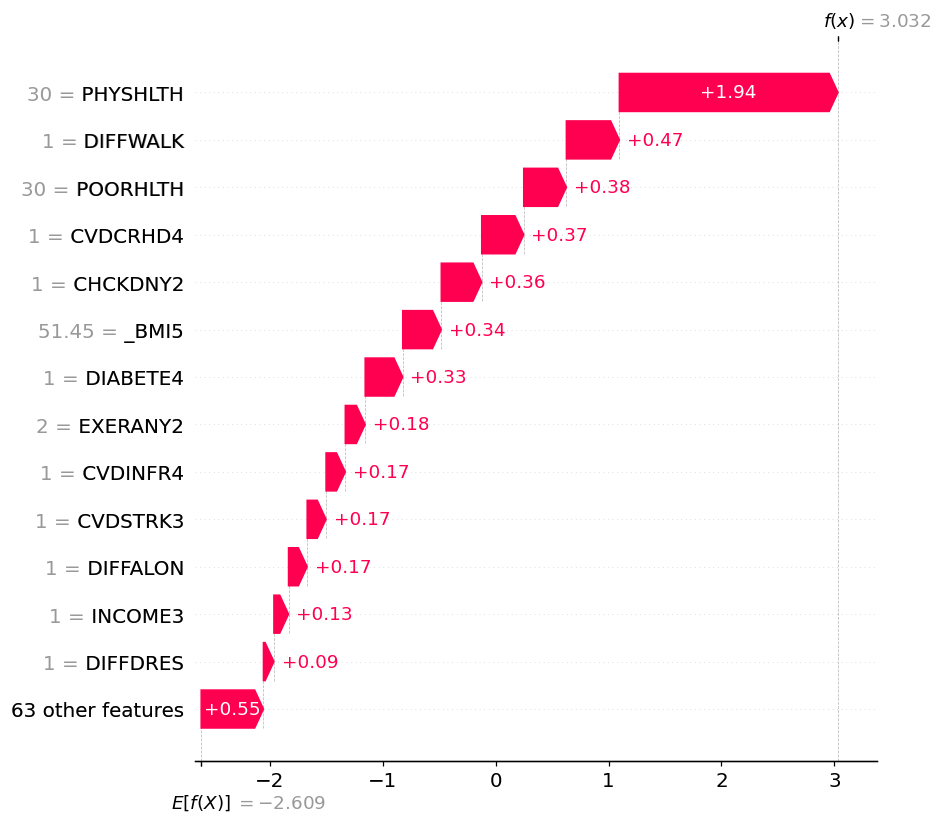

SHAP-vs-gain rank agreement: Spearman rho = 0.911 (p = 3.6e-30, n = 76)  [committed meta: 0.911]

global importance, top-5 by mean|SHAP| (vs P5 gain rank):
 rank   column  mean_abs_shap  p5_gain_rank
    1 PHYSHLTH         0.6813             1
    2 DIFFWALK         0.2164             2
    3 DIABETE4         0.1981             3
    4    _BMI5         0.1855             6
    5    EDUCA         0.1786             5
[section time] S13 SHAP waterfall (stored values) + SHAP-vs-gain rank agreement: 0.2s


In [26]:
import shap

with timed("S13 SHAP waterfall (stored values) + SHAP-vs-gain rank agreement"):
    sc = pd.read_parquet(RESULTS / "p7" / "shap_cases.parquet")
    row_A = int(sc.loc["A", "_row_index"]); base = float(sc.loc["A", "_base_value"])
    vals = sc.loc["A"].drop(["_base_value", "_row_index"]).to_numpy(dtype=float)
    expl = shap.Explanation(values=vals, base_values=base,
                            data=X.iloc[row_A].to_numpy(dtype=float),
                            feature_names=list(X.columns))
    shap.plots.waterfall(expl, max_display=14)
    plt.show()

    si = pd.read_csv(RESULTS / "p7" / "shap_global_importance.csv")
    rho, pv = stats.spearmanr(si["rank"], si["p5_gain_rank"])
    print(f"SHAP-vs-gain rank agreement: Spearman rho = {rho:.3f} (p = {pv:.2g}, n = 76)  [committed meta: 0.911]")
    print("\nglobal importance, top-5 by mean|SHAP| (vs P5 gain rank):")
    print(si.head(5)[["rank", "column", "mean_abs_shap", "p5_gain_rank"]].round(4).to_string(index=False))

**Interpretation.**
- **Taxonomy** (live numbers = committed `results/p7/error_taxonomy.csv`): TP 38,957 / FP 14,340 / TN 350,451 / FN 33,784 — FPR 3.9%, but **FNR 46.4%** at the default 0.5 threshold against a 16.6% prevalence: the model is *uncalibrated for balanced errors*, exactly the trade-off section 10 predicted (AUC is threshold-free; operating points are not).
- **The 3/4 boundary is the story**: class-3 FPs + class-4 FNs = **88.2% of all errors**. The model's confusion is not random noise — it is the Good/Fair boundary itself being fuzzy (self-rated health is a noisy human summary).
- **41,091 rows (9.4%) are wrong in all three models** — a systematically hard residue, not ensemble noise; 87% of rows are gotten right by every model.
- **Case A** (row 307,041): y=0 (GENHLTH=3, "Good") yet OOF p=0.96 — the waterfall shows `PHYSHLTH` pushing **+1.94 log-odds** almost single-handedly: the respondent reports many poor-health days while *self-rating* Good. The model is reading real morbidity signal against the label — a boundary respondent, not a bug.
- **Two importance lenses agree**: SHAP (tuned model, per-prediction attribution) vs split-gain (untuned EXP-006) ranks correlate at **ρ = 0.911**; `PHYSHLTH` is #1 in both. The gain→SHAP differences are collinear features sharing credit (e.g. the functional-limitation block), as expected with path-dependent TreeExplainer.

## 14 — Conclusions & self-verification

**ADR-006 (final model & freeze).** The final recommended model is the **tuned LightGBM (EXP-014a)** — params verbatim (`n_estimators=512, learning_rate=0.0219, num_leaves=94, min_child_samples=44, subsample=0.816, colsample_bytree=0.598, reg_lambda=3.12, random_state=42`) inside the NaN-passthrough pipeline. **Two stated numbers**: canonical 10-fold **0.904321 ± 0.001675** (the headline; `code.py --full` reproduces it to ≤4.8e-7 per fold) and the unbiased nested-CV estimate **0.904303** (optimism +0.000018 — negligible). Runner-up tuned XGBoost was rejected on Wilcoxon T1 (10/10 folds favour LGBM, W=0, p=0.00195); best pure-sklearn family (HistGB 0.903220) loses by ≈0.011 at family level; further iteration was rejected because nested CV shows the search width was already sufficient. Everything is frozen: any model/fold/feature change from here requires a new ADR.

**Self-check.** The final cell compares **this notebook's own fold means** (collected in `NB_SCORES` as the sections ran) against `results/experiments_log.csv`, tolerance 1e-6 (the log stores 6 decimals, so exact replication shows per-fold deltas ≤ ~5e-7). If any row prints FAIL, this notebook diverged from the project — by construction of the replay it should not.

In [27]:
with timed("S14 final self-check vs results/experiments_log.csv"):
    checks = [
        ("EXP-001",  "Dummy (prior) - sanity floor"),
        ("EXP-002a", "LogReg C=0.01 - linear reference"),
        ("EXP-002c", "LogReg C=1 - flat-C-grid point"),
        ("EXP-003i", "DecisionTree (16, 200) - grid winner"),
        ("EXP-003l", "DecisionTree (None, 1) - overfit collapse"),
        ("EXP-004",  "RandomForest"),
        ("EXP-005",  "HistGradientBoosting"),
        ("EXP-006",  "LightGBM (untuned)"),
        ("EXP-007",  "XGBoost (untuned)"),
        ("EXP-014a", "tuned LightGBM - FINAL MODEL"),
        ("EXP-012a", "LGBM on H1-subset (36 cols)"),
        ("EXP-012c", "LGBM on complement (40 cols)"),
    ]
    rows, all_ok = [], True
    for exp_id, label in checks:
        if exp_id not in NB_SCORES:
            rows.append([exp_id, label, "-", "-", "-", "-", "FAIL (missing)"]); all_ok = False; continue
        nb = NB_SCORES[exp_id]
        lf, lm = log_folds(exp_id)
        d_mean = float(nb.mean() - lm); d_fold = float(np.abs(nb - lf).max())
        ok = abs(d_mean) <= 1e-6
        all_ok &= ok
        rows.append([exp_id, label, f"{nb.mean():.6f}", f"{lm:.6f}", f"{d_mean:+.1e}", f"{d_fold:.1e}",
                     "PASS" if ok else "FAIL"])
    check_tab = pd.DataFrame(rows, columns=["exp_id", "run", "notebook mean", "logged mean",
                                            "mean delta", "max fold delta", "verdict"])
    print(check_tab.to_string(index=False))

    # informational (deterministic replays, not in the mandated check set)
    for exp_id, src in [("EXP-011a-200", "kbest-200"), ("EXP-013-100", "PCA-100")]:
        if exp_id in NB_SCORES:
            lf, lm = log_folds(exp_id)
            nb = NB_SCORES[exp_id]
            print(f"[info] {exp_id} ({src}): notebook {nb.mean():.6f} vs logged {lm:.6f} "
                  f"(max fold delta {np.abs(nb - lf).max():.1e})")
    print()
    print("per-section wall times (this run):")
    print(pd.Series(SECTION_TIMES).round(1).sort_index().to_string())
    assert all_ok, "SELF-CHECK FAILED - a replay diverged from experiments_log.csv!"
    print("\nALL CHECKS PASS - this notebook reproduces results/experiments_log.csv on the canonical folds.")

  exp_id                                       run notebook mean logged mean mean delta max fold delta verdict
 EXP-001              Dummy (prior) - sanity floor      0.500000    0.500000   +0.0e+00        0.0e+00    PASS
EXP-002a          LogReg C=0.01 - linear reference      0.892588    0.892588   +8.6e-08        4.1e-07    PASS
EXP-002c            LogReg C=1 - flat-C-grid point      0.892580    0.892580   -2.0e-07        4.7e-07    PASS
EXP-003i      DecisionTree (16, 200) - grid winner      0.880206    0.880206   -9.3e-08        4.5e-07    PASS
EXP-003l DecisionTree (None, 1) - overfit collapse      0.694922    0.694922   -4.4e-07        5.0e-07    PASS
 EXP-004                              RandomForest      0.893315    0.893315   -3.0e-07        4.0e-07    PASS
 EXP-005                      HistGradientBoosting      0.903220    0.903220   +4.3e-07        4.3e-07    PASS
 EXP-006                        LightGBM (untuned)      0.903355    0.903355   -3.8e-07        3.7e-07    PASS
 

### Where every number lives (closing pointers)

| number | authoritative source |
|---|---|
| every fold AUC / mean AUC in this notebook | `results/experiments_log.csv` (42 rows; exp ids quoted per section) |
| fold identity (`folds_sha256=3b3a17457039`) | notes field of every scored log row; recomputed in section 1 |
| decisions & rationale | `vault/30 Decisions/ADR-001…006` |
| leakage rules & tiers | `vault/40 Data Notes/Leakage watchlist.md` |
| search tables / winners / Wilcoxon / nested CV | `results/p6/` (`search_cv_*.csv`, `best_params.json`, `wilcoxon_tests.csv`, `nested_cv_details.csv`) |
| selection artifacts | `results/p5/` (`subsets.json`, `lgbm_importance.csv`, `kbest_selection.csv`, `pca_variance.csv`) |
| error analysis & SHAP | `results/p7/` + `data/interim/oof_predictions.parquet` |
| graded reproduction | `deliverables/code.py` (`--full` re-runs EXP-014a) → `results/final_run_*` |
| the report | `deliverables/report/report.pdf` |

*Personal learning artifact — not a course deliverable. The evaluated deliverable is `deliverables/code.py`.*